# Predicción de deserción estudiantil con PyCaret

**Problema:** clasificar a cada estudiante en `Dropout` (deserta), `Enrolled` (sigue matriculado) o `Graduate` (se gradúa). El interés principal es **detectar a los desertores**.

```
datos ──► exploración ──► preprocesamiento ──► balanceo ──► comparar modelos ──► calibrar ──► evaluar ──► exportar ──► uv run app
```

> Abre el cuaderno en VS Code y escoge el kernel del proyecto (`.venv`). Ejecuta las celdas **en orden**.

## Resumen de resultados

**Modelo final:** Random Forest + SMOTE + calibración sigmoid. Usa 34 variables, incluidas las notas de 1.er y 2.º semestre.

| Métrica | Validación cruzada | Prueba (885 estudiantes) | IC 95 % en prueba |
|---|---|---|---|
| Recall Dropout | 0.761 | 0.764 | 0.714 – 0.812 |
| F1 macro | 0.706 | 0.715 | 0.682 – 0.747 |
| Balanced Accuracy | 0.697 | 0.707 | 0.675 – 0.739 |

En prueba, el modelo **detecta 217 de 284 desertores (76 %)** y **82 % de sus alertas son correctas**. La clase `Enrolled` es la más débil (recall 45 %).

## Contenido

| Sección | Qué responde |
|---|---|
| Pasos 1–3 | Datos, calidad y exploración |
| Guía de métricas | Qué métricas sirven para detección y por qué |
| Paso 4 | Preprocesamiento y balanceo |
| Pasos 5–6 | Comparación de modelos, tablas y gráficas |
| Paso 7 | Por qué Random Forest, ajuste y calibración |
| Paso 8 y anexo | Resultados en prueba |
| Pasos 9–10 | Exportación y comprobación |
| Anexo y cierre | Predicción temprana y limitaciones |

## Paso 1 · Importar librerías

**Qué se usa:** `pandas` y `numpy` (datos), `matplotlib` y `seaborn` (gráficas), `pycaret` (preprocesamiento y comparación), `scikit-learn` (modelos, métricas, validación cruzada) e `imbalanced-learn` (SMOTE, se importa más adelante).

`SEMILLA = 42` se fija para que particiones, SMOTE y modelos sean reproducibles.

In [1]:
%pip install -q seaborn pycaret

/home/cuellarmaster/Escritorio/Aprendizaje Automatico/Proyecto final/pycaret-inno/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import re
import warnings
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pycaret.classification import *
from sklearn.metrics import balanced_accuracy_score, recall_score   # NUEVO: métricas del EDA


from clasificador_desertores.core import CARPETA_MODELO, COLUMNAS, NOMBRE_MODELO

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

SEMILLA = 42
np.random.seed(SEMILLA)

CLASES = ["Dropout", "Enrolled", "Graduate"]
COLORES = {"Dropout": "#d62728", "Enrolled": "#ff9f1c", "Graduate": "#2ca02c"}

print("pandas", pd.__version__, "| seaborn", sns.__version__)
print(f'El modelo se guardará en: "{CARPETA_MODELO}"')

pandas 2.1.4 | seaborn 0.13.2
El modelo se guardará en: "/home/cuellarmaster/Escritorio/Aprendizaje Automatico/Proyecto final/pycaret-inno/modelo"


## Paso 2 · Cargar los datos

**Fuente:** repositorio UCI, dataset 697, *Predict Students' Dropout and Academic Success*, descargado con `ucimlrepo`.

La celda hace cinco cosas:

1. **Descarga** variables y objetivo: 4424 filas × 37 columnas.
2. **Estandariza nombres** (`Curricular units 1st sem` → `CU1`, `2nd sem` → `CU2`, se corrige `Nacionality`, se quitan paréntesis y espacios).
3. **Elimina** `Previous_qualification_grade` y `Admission_grade` para trabajar con las mismas variables del análisis exploratorio (EDA): 34 de entrada + `Target`.
4. **Verifica la calidad.**
5. **Agrupa las variables** por tipo y comprueba que cada una esté en un solo grupo.

In [3]:
# %pip install -q ucimlrepo
from ucimlrepo import fetch_ucirepo

# ── 1. Descarga desde la API de UCI (id 697: Predict Students' Dropout and Academic Success)
dataset = fetch_ucirepo(id=697)
df = pd.concat([dataset.data.features, dataset.data.targets], axis=1)
print("Dimensiones al descargar:", df.shape)

# ── 2. Estandarizar nombres (misma función que el EDA)
def limpiar_nombre(c):
    c = (c.replace("Curricular units 1st sem", "CU1").replace("Curricular units 2nd sem", "CU2")
          .replace("Nacionality", "Nationality").replace("Daytime/evening attendance", "Daytime_attendance")
          .replace("without evaluations", "no_evals"))
    c = re.sub(r"[()']", "", c).strip()
    return c.replace(" ", "_")

df.columns = [limpiar_nombre(c) for c in df.columns]

# ── 3. Igualar con el EDA: mismo nombre y mismas 34 variables de entrada
df = df.rename(columns={"Marital_Status": "Marital_status"})
df = df.drop(columns=["Previous_qualification_grade", "Admission_grade"])
print("Dimensiones finales:", df.shape,)

# ── 4. Calidad de datos (la API devuelve lo mismo que dataset.csv, pero se verifica)
print("\nNulos totales:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
print("Clases encontradas:", sorted(df["Target"].unique()), "| esperadas:", CLASES)

# ── 5. Grupos de variables (los mismos del EDA, sección 3.5)
bin_cols = ["Daytime_attendance", "Displaced", "Educational_special_needs", "Debtor",
            "Tuition_fees_up_to_date", "Gender", "Scholarship_holder", "International"]
ord_cols = ["Application_order"]
nom_cols = ["Marital_status", "Application_mode", "Course", "Previous_qualification", "Nationality",
            "Mothers_qualification", "Fathers_qualification", "Mothers_occupation", "Fathers_occupation"]
num_cols = [c for c in df.columns if c not in bin_cols + ord_cols + nom_cols + ["Target"]]

# Cada columna de entrada debe pertenecer a un único grupo
assert sorted(bin_cols + ord_cols + nom_cols + num_cols) == sorted(df.columns.drop("Target")), \
    "Hay columnas sin clasificar: revisa los nombres tras limpiar_nombre()"

categoricas = nom_cols          # una sola fuente de verdad para setup() de PyCaret
print(f"\nBinarias: {len(bin_cols)} | Ordinal: {len(ord_cols)} | "
      f"Nominales: {len(nom_cols)} | Numéricas: {len(num_cols)}")

df.head()

Dimensiones al descargar: (4424, 37)
Dimensiones finales: (4424, 35)

Nulos totales: 0
Filas duplicadas: 0
Clases encontradas: ['Dropout', 'Enrolled', 'Graduate'] | esperadas: ['Dropout', 'Enrolled', 'Graduate']

Binarias: 8 | Ordinal: 1 | Nominales: 9 | Numéricas: 16


,Marital_status,Application_mode,Application_order,Course,Daytime_attendance,Previous_qualification,Nationality,Mothers_qualification,Fathers_qualification,Mothers_occupation,Fathers_occupation,Displaced,Educational_special_needs,Debtor,Tuition_fees_up_to_date,Gender,Scholarship_holder,Age_at_enrollment,International,CU1_credited,CU1_enrolled,CU1_evaluations,CU1_approved,CU1_grade,CU1_no_evals,CU2_credited,CU2_enrolled,CU2_evaluations,CU2_approved,CU2_grade,CU2_no_evals,Unemployment_rate,Inflation_rate,GDP,Target
0,1,17,5,171,1,1,1,19,12,5,9,1,0,0,1,1,0,20,0,0,0,0,0,0.000,0,0,0,0,0,0.000,0,10.800,1.400,1.740,Dropout
1,1,15,1,9254,1,1,1,1,3,3,3,1,0,0,0,1,0,19,0,0,6,6,6,14.000,0,0,6,6,6,13.667,0,13.900,-0.300,0.790,Graduate
2,1,1,5,9070,1,1,1,37,37,9,9,1,0,0,0,1,0,19,0,0,6,0,0,0.000,0,0,6,0,0,0.000,0,10.800,1.400,1.740,Dropout
3,1,17,2,9773,1,1,1,38,37,5,3,1,0,0,1,0,0,20,0,0,6,8,6,13.429,0,0,6,10,5,12.400,0,9.400,-0.800,-3.120,Graduate
4,2,39,1,8014,0,1,1,37,38,9,9,0,0,0,1,0,0,45,0,0,6,9,5,12.333,0,0,6,6,6,13.000,0,13.900,-0.300,0.790,Graduate


### Cómo leer esta salida

| Revisión | Resultado | Implicación |
|---|---|---|
| Dimensiones | 4424 × 35 | 34 variables de entrada + `Target` |
| Valores nulos | 0 | No hay datos que reparar |
| Filas duplicadas | 0 | No se eliminan filas |
| Clases | `Dropout`, `Enrolled`, `Graduate` | Problema **multiclase** (3 clases) |

| Grupo | Cantidad | Variables / ejemplos | Tratamiento |
|---|---|---|---|
| Binarias | 8 | `Debtor`, `Gender`, `Scholarship_holder`, `Tuition_fees_up_to_date` | Ya vienen como 0/1 |
| Ordinal | 1 | `Application_order` | Se conserva su orden numérico |
| Nominales | 9 | `Course`, `Nationality`, ocupación y estudios de los padres | Son **códigos**, no cantidades: se tratan como categorías |
| Numéricas | 16 | Materias y notas por semestre, edad, desempleo, inflación, PIB | Cantidades |

`df.head()` muestra las primeras 5 filas como control visual de la carga.

## Paso 3 · Explorar los datos

¿Cuántos estudiantes hay en cada clase? ¿Qué variables los diferencian?

In [4]:
df["Target"].value_counts()

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

### Distribución de clases: el dataset está desbalanceado

| Clase | Estudiantes | Porcentaje |
|---|---|---|
| Graduate | 2209 | 49.9 % |
| Dropout | 1421 | 32.1 % |
| Enrolled | 794 | 17.9 % |**texto en negrita**

- Hay **2.8 graduados por cada estudiante `Enrolled`**. El desbalance es moderado y viene así en los datos originales.
- **Consecuencia 1:** un modelo que responda siempre `Graduate` acierta cerca del 50 % sin detectar ningún desertor. Por eso *Accuracy* no basta.
- **Consecuencia 2:** el modelo tiende a aprender peor las clases con menos ejemplos. Esto se trata en el Paso 4 con balanceo.

In [5]:
df.describe().round(2)

,Marital_status,Application_mode,Application_order,Course,Daytime_attendance,Previous_qualification,Nationality,Mothers_qualification,Fathers_qualification,Mothers_occupation,Fathers_occupation,Displaced,Educational_special_needs,Debtor,Tuition_fees_up_to_date,Gender,Scholarship_holder,Age_at_enrollment,International,CU1_credited,CU1_enrolled,CU1_evaluations,CU1_approved,CU1_grade,CU1_no_evals,CU2_credited,CU2_enrolled,CU2_evaluations,CU2_approved,CU2_grade,CU2_no_evals,Unemployment_rate,Inflation_rate,GDP
count,"4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000","4,424.000"
mean,1.180,18.670,1.730,"8,856.640",0.890,4.580,1.870,19.560,22.280,10.960,11.030,0.550,0.010,0.110,0.880,0.350,0.250,23.270,0.020,0.710,6.270,8.300,4.710,10.640,0.140,0.540,6.230,8.060,4.440,10.230,0.150,11.570,1.230,0.000
std,0.610,17.480,1.310,"2,063.570",0.310,10.220,6.910,15.600,15.340,26.420,25.260,0.500,0.110,0.320,0.320,0.480,0.430,7.590,0.160,2.360,2.480,4.180,3.090,4.840,0.690,1.920,2.200,3.950,3.010,5.210,0.750,2.660,1.380,2.270
min,1.000,1.000,0.000,33.000,0.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,17.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,7.600,-0.800,-4.060
25%,1.000,1.000,1.000,"9,085.000",1.000,1.000,1.000,2.000,3.000,4.000,4.000,0.000,0.000,0.000,1.000,0.000,0.000,19.000,0.000,0.000,5.000,6.000,3.000,11.000,0.000,0.000,5.000,6.000,2.000,10.750,0.000,9.400,0.300,-1.700
50%,1.000,17.000,1.000,"9,238.000",1.000,1.000,1.000,19.000,19.000,5.000,7.000,1.000,0.000,0.000,1.000,0.000,0.000,20.000,0.000,0.000,6.000,8.000,5.000,12.290,0.000,0.000,6.000,8.000,5.000,12.200,0.000,11.100,1.400,0.320
75%,1.000,39.000,2.000,"9,556.000",1.000,1.000,1.000,37.000,37.000,9.000,9.000,1.000,0.000,0.000,1.000,1.000,0.000,25.000,0.000,0.000,7.000,10.000,6.000,13.400,0.000,0.000,7.000,10.000,6.000,13.330,0.000,13.900,2.600,1.790
max,6.000,57.000,9.000,"9,991.000",1.000,43.000,109.000,44.000,44.000,194.000,195.000,1.000,1.000,1.000,1.000,1.000,1.000,70.000,1.000,20.000,26.000,45.000,26.000,18.880,12.000,19.000,23.000,33.000,20.000,18.570,12.000,16.200,3.700,3.510


### Tabla de estadísticas descriptivas (`describe`)

Filas: `count` (datos), `mean` (promedio), `std` (dispersión), `min`, `max` y cuartiles (`25%`, `50%` = mediana, `75%`).

| Observación | Evidencia |
|---|---|
| No faltan datos | `count` = 4424 en todas las columnas |
| La mayoría estudia de día | media de `Daytime_attendance` = 0.89 |
| Pocos son deudores | media de `Debtor` = 0.11 (11 %) |
| La mayoría tiene la matrícula al día | `Tuition_fees_up_to_date` = 0.88 |
| Población joven con casos mayores | edad: mediana 20, media 23.3, máximo 70 |
| Materias aprobadas por semestre | 4.71 en promedio en el 1.º y 4.44 en el 2.º |
| Escalas muy distintas | por ejemplo, `GDP` va de -4.06 a 3.51 y `CU1_evaluations` de 0 a 45; de ahí la estandarización |

>En las columnas nominales (`Course`, `Nationality`, ocupaciones, etc.) la media y la desviación **no tienen significado**, porque los números son códigos. En las binarias, la media es la proporción de unos.

In [6]:
# Promedio de cada medida por especie
df.groupby("Target").mean().round(2)

,Marital_status,Application_mode,Application_order,Course,Daytime_attendance,Previous_qualification,Nationality,Mothers_qualification,Fathers_qualification,Mothers_occupation,Fathers_occupation,Displaced,Educational_special_needs,Debtor,Tuition_fees_up_to_date,Gender,Scholarship_holder,Age_at_enrollment,International,CU1_credited,CU1_enrolled,CU1_evaluations,CU1_approved,CU1_grade,CU1_no_evals,CU2_credited,CU2_enrolled,CU2_evaluations,CU2_approved,CU2_grade,CU2_no_evals,Unemployment_rate,Inflation_rate,GDP
Target,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Dropout,1.260,23.710,1.590,"8,755.630",0.850,5.310,1.960,21.040,22.680,10.120,10.140,0.470,0.010,0.220,0.680,0.490,0.090,26.070,0.020,0.610,5.820,7.750,2.550,7.260,0.190,0.450,5.780,7.170,1.940,5.900,0.240,11.620,1.280,-0.150
Enrolled,1.150,19.800,1.630,"8,868.810",0.910,4.790,2.080,17.620,20.920,14.720,14.460,0.550,0.010,0.110,0.950,0.390,0.160,22.370,0.030,0.510,5.960,9.340,4.320,11.130,0.180,0.360,5.940,9.440,4.060,11.120,0.190,11.270,1.210,0.050
Graduate,1.130,15.020,1.850,"8,917.250",0.910,4.030,1.750,19.310,22.500,10.150,10.370,0.600,0.010,0.050,0.990,0.250,0.380,21.780,0.020,0.850,6.670,8.280,6.230,12.640,0.090,0.670,6.630,8.140,6.180,12.700,0.080,11.640,1.200,0.080


###Promedios por clase: qué diferencia a los desertores

| Variable | Dropout | Enrolled | Graduate |
|---|---|---|---|
| Materias aprobadas 1.er sem. (`CU1_approved`) | **2.55** | 4.32 | 6.23 |
| Materias aprobadas 2.º sem. (`CU2_approved`) | **1.94** | 4.06 | 6.18 |
| Nota 1.er sem. (`CU1_grade`) | **7.26** | 11.13 | 12.64 |
| Nota 2.º sem. (`CU2_grade`) | **5.90** | 11.12 | 12.70 |
| Matrícula al día | **68 %** | 95 % | 99 % |
| Deudores | **22 %** | 11 % | 5 % |
| Con beca | **9 %** | 16 % | 38 % |
| Edad al ingresar | **26.1** | 22.4 | 21.8 |

**Interpretación:**
- El **rendimiento académico** muestra diferencias grandes: quienes desertan aprueban menos materias y tienen notas promedio más bajas.
- En lo **económico**, entre los desertores hay más atrasos de matrícula, más deudores y menos becados.
- `Enrolled` queda **en medio** y, en notas, está mucho más cerca de `Graduate`. Esto anticipa que será la clase más difícil.
- Son **asociaciones**, no prueban que estas variables causen la deserción.
- Los promedios de variables nominales (códigos) no se interpretan.

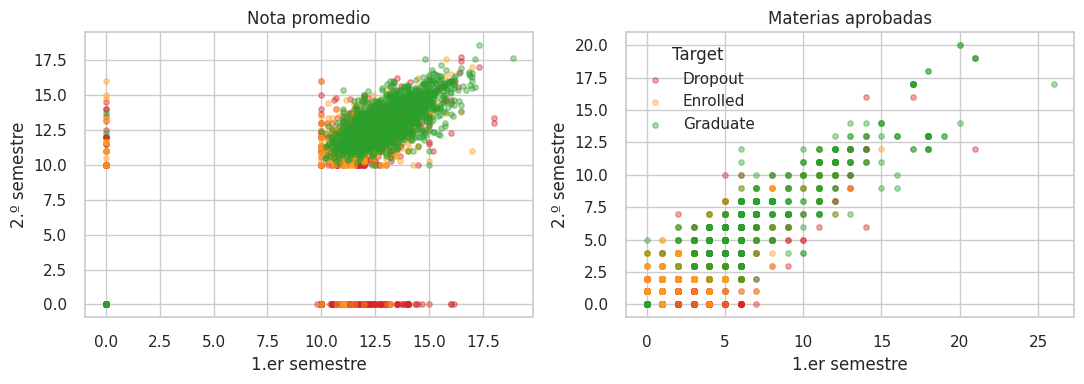

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for clase in CLASES:
    grupo = df[df["Target"] == clase]
    ejes[0].scatter(grupo["CU1_grade"], grupo["CU2_grade"], label=clase, c=COLORES[clase], alpha=0.4, s=15)
    ejes[1].scatter(grupo["CU1_approved"], grupo["CU2_approved"], label=clase, c=COLORES[clase], alpha=0.4, s=15)
ejes[0].set(title="Nota promedio", xlabel="1.er semestre", ylabel="2.º semestre")
ejes[1].set(title="Materias aprobadas", xlabel="1.er semestre", ylabel="2.º semestre")
ejes[1].legend(title="Target")
plt.tight_layout()
plt.show()

###Gráficas de dispersión: 1.er semestre frente a 2.º semestre

Cada punto es un estudiante; el color indica su clase (rojo `Dropout`, naranja `Enrolled`, verde `Graduate`).

**Izquierda, nota promedio**
- La nube principal sigue una diagonal: quien tiene buena nota en el 1.er semestre suele mantenerla en el 2.º.
- Las notas altas tienen sobre todo puntos verdes.
- Hay puntos sobre los ejes (nota 0 en un semestre). En la franja de nota 0 en el 2.º semestre se ven muchos puntos rojos y naranjas.
- Un 0 es el promedio registrado; la gráfica por sí sola no indica si el estudiante reprobó o no fue evaluado.

**Derecha, materias aprobadas**
- También hay relación diagonal entre semestres.
- Cerca de 0 materias aprobadas se ven muchos casos rojos y naranjas; con más materias aprobadas predomina el verde.

**Conclusión:** estas variables ayudan a separar las clases, pero hay **mucha superposición**, así que no bastan dos variables ni una regla simple. Como los puntos se dibujan unos encima de otros, el color visible no permite estimar proporciones; para eso está la tabla anterior.

>Las materias aprobadas y las notas parecen las señales más útiles. La gráfica de importancia de variables (Paso 6) lo contrasta con el modelo.

---
## Guía de métricas: cuáles usar para detectar deserción

Para la clase `Dropout`, cada predicción es de uno de estos tipos (cifras del modelo final en prueba):

| | Qué significa | Cantidad |
|---|---|---|
| Verdadero positivo (VP) | Desertor y el modelo lo marcó | 217 |
| Falso negativo (FN) | Desertor que **se escapó** | 67 |
| Falso positivo (FP) | **Falsa alarma** | 47 |
| Verdadero negativo (VN) | No desertor y no marcado | 554 |

| Métrica | Fórmula | Pregunta que responde | Papel en este proyecto |
|---|---|---|---|
| **Recall Dropout** (sensibilidad) | VP / (VP + FN) = 217/284 = **0.764** | De los desertores reales, ¿cuántos detecto? | ⭐ **Principal para detección** |
| **Precisión Dropout** | VP / (VP + FP) = 217/264 = **0.822** | De las alertas, ¿cuántas son correctas? | ⭐ **Acompaña siempre al recall** |
| **F1 Dropout** | media armónica de ambas = **0.792** | ¿Qué tan equilibrada es la detección? | Resume la detección |
| **F1 macro** | promedio simple del F1 de las 3 clases | ¿Funciona bien en todas las clases? | ⭐ **Criterio de selección** |
| **Balanced Accuracy** | promedio simple del recall de las 3 clases | ¿Cuánto acierta dando el mismo peso a cada clase? | Apoyo; ordena `compare_models` |
| **AUC OvR macro** | área ROC de cada clase contra el resto | ¿Qué tan bien ordena por probabilidad, sin fijar un corte? | Apoyo |
| **Log loss / Brier** | error de las probabilidades (menor es mejor) | ¿Son confiables los porcentajes? | ⭐ Para elegir la calibración |
| Accuracy | aciertos / total | ¿Cuántos acierto en total? | Solo referencia |
| Kappa / MCC | acuerdo corregido por azar / correlación | ¿Es mejor que el azar? | Referencia |

### Por qué estas métricas

- **No basta Accuracy:** responder siempre `Graduate` da cerca de 0.50 de accuracy y **0 de recall de Dropout**.
- **Recall es prioritario** porque un falso negativo es un estudiante en riesgo que no recibe apoyo. Se asume que esto cuesta más que revisar una falsa alarma; es una decisión que debe validar la institución.
- **Recall solo es engañoso:** marcar a todos como desertores daría recall 1.00, con precisión de apenas 0.32. Por eso se revisa la precisión.
- **F1 macro** pesa igual las tres clases, así que no se puede mejorar atendiendo solo a la mayoritaria.
- Si la institución quisiera dar explícitamente más peso al recall, una alternativa es **F2** (no se calculó aquí).

> **Criterio usado para escoger:** F1 macro en validación cruzada, vigilando que el Recall de Dropout no empeore.

## Paso 4 · Preprocesamiento y partición

`setup()` separa **80 % para entrenamiento (3539)** y **20 % para prueba (885)**, conservando la proporción de clases (estratificado, opción por defecto de PyCaret). Además arma el pipeline de preprocesamiento. `session_id=42` permite repetir los resultados.

### Preprocesamiento común

| Paso | Configuración | Para qué sirve |
|---|---|---|
| Nominales a texto | `astype(str)` en 9 columnas | Evita interpretar códigos como cantidades |
| Imputación numérica | `numeric_imputation="median"` | La mediana resiste valores extremos. Como hay 0 nulos, no cambia el entrenamiento |
| Categorías raras | `rare_to_value=0.01`, `rare_value="rara"` | Une categorías con menos del 1 % para reducir columnas con muy pocos datos |
| One-hot encoding | `max_encoding_ohe=100` | Convierte cada categoría en una columna 0/1 |
| Codificación del objetivo | automática | `Dropout`=0, `Enrolled`=1, `Graduate`=2 |

**Resultado:** de 34 variables se pasa a **103 columnas**.

### Cuatro variantes comparadas

| Variante | Qué añade | Idea que se prueba | Balanceo en la comparación |
|---|---|---|---|
| P1 estandarización | z-score: (x − media) / desviación | Igualar escalas | `class_weight="balanced"` |
| P2 Yeo-Johnson | transformación de potencia | Reducir asimetría; admite ceros y negativos | `class_weight="balanced"` |
| P3 PCA | z-score + PCA (`pca_components=0.95`) | Reducir dimensiones | `class_weight="balanced"` |
| P4 SMOTE | z-score + SMOTE | Balancear con ejemplos sintéticos | SMOTE |

Se evalúan con **Regresión Logística** y validación cruzada (CV) estratificada de 5 pliegues. La regla de esta primera ronda es: tomar el mayor F1 macro y, si una variante más simple queda a menos de una desviación estándar, preferirla.

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# ── 1. Datos: las nominales son códigos, se pasan a texto para que PyCaret las trate como categorías
categoricas = nom_cols
df_modelo = df.copy()
df_modelo[categoricas] = df_modelo[categoricas].astype(str)

# ── 2. Parámetros comunes a todas las metodologías
BASE = dict(
    data=df_modelo,
    target="Target",
    categorical_features=categoricas,
    session_id=SEMILLA,
    train_size=0.8,                    # 80 % entrenar / 20 % probar (igual que el EDA)
    fold=5,
    numeric_imputation="median",       # técnica 1: imputación por mediana
    rare_to_value=0.01,                # técnica 3: agrupar categorías con menos del 1 % de las filas
    rare_value="rara",
    max_encoding_ohe=100,              # técnica 3: one-hot en todas las categóricas
    verbose=False,
)

# ── 3. Lo que cambia en cada metodología (equivalen a P1-P4 de la sección 14 del EDA)
CONFIGS = {
    "P1_estandarizacion": dict(normalize=True, normalize_method="zscore"),
    "P2_yeo_johnson":     dict(transformation=True, transformation_method="yeo-johnson"),
    "P3_pca":             dict(normalize=True, normalize_method="zscore",
                               pca=True, pca_method="linear", pca_components=0.95),
    "P4_smote":           dict(normalize=True, normalize_method="zscore",
                               fix_imbalance=True, fix_imbalance_method="smote"),
}

# ── 4. Comparar: PyCaret pre-procesa, scikit-learn evalúa con CV estratificada de 5 pliegues
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

filas = {}
for nombre, params in CONFIGS.items():
    # En la comparación SMOTE lo aplica el pipeline de imblearn (solo en los pliegues de entrenamiento),
    # así que se quita de setup() para no aplicarlo dos veces.
    params_setup = {k: v for k, v in params.items() if not k.startswith("fix_imbalance")}
    setup(**BASE, **params_setup)

    X = get_config("X_train_transformed")      # ya pre-procesado por PyCaret
    y = get_config("y_train_transformed")

    if nombre == "P4_smote":
        modelo = ImbPipeline([("smote", SMOTE(random_state=SEMILLA)),
                              ("clf", LogisticRegression(max_iter=3000))])
    else:
        modelo = LogisticRegression(max_iter=3000, class_weight="balanced")

    r = cross_validate(modelo, X, y, cv=cv, n_jobs=-1,
                       scoring=["f1_macro", "balanced_accuracy", "accuracy"])
    filas[nombre] = {
        "Columnas finales": X.shape[1],
        "F1 Macro": r["test_f1_macro"].mean(),
        "F1 Macro (std)": r["test_f1_macro"].std(),
        "Balanced Acc": r["test_balanced_accuracy"].mean(),
        "Accuracy": r["test_accuracy"].mean(),
    }

comp_prep = pd.DataFrame(filas).T.sort_values("F1 Macro", ascending=False)
display(comp_prep.style.format({
    "Columnas finales": "{:.0f}", "F1 Macro": "{:.3f}", "F1 Macro (std)": "{:.3f}",
    "Balanced Acc": "{:.3f}", "Accuracy": "{:.3f}",
}).background_gradient(subset=["F1 Macro"], cmap="Greens"))

# ── 5. Elegir: mayor F1 macro; si otra queda dentro de 1 desviación, se prefiere la más simple
orden = list(CONFIGS)                                  # de la más simple a la más compleja
mejor = comp_prep["F1 Macro"].idxmax()
umbral = comp_prep.loc[mejor, "F1 Macro (std)"]
empatadas = [v for v in orden
             if comp_prep.loc[mejor, "F1 Macro"] - comp_prep.loc[v, "F1 Macro"] <= umbral]
PREP_ELEGIDA = empatadas[0]
print(f"\nMayor F1 macro: {mejor} | Empatadas: {empatadas} | Elegida: {PREP_ELEGIDA}")

# ── 6. setup() definitivo con la metodología ganadora (aquí sí va fix_imbalance si ganó P4)
exp = setup(**BASE, **CONFIGS[PREP_ELEGIDA])
print("Variante:", PREP_ELEGIDA)
print("Entrada:", get_config("X_train").shape,
      "| Transformado:", get_config("X_train_transformed").shape)

/home/cuellarmaster/Escritorio/Aprendizaje Automatico/Proyecto final/pycaret-inno/.venv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/cuellarmaster/Escritorio/Aprendizaje Automatico/Proyecto final/pycaret-inno/.venv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also re

,Columnas finales,F1 Macro,F1 Macro (std),Balanced Acc,Accuracy
P1_estandarizacion,103,0.712,0.016,0.719,0.753
P4_smote,103,0.708,0.011,0.714,0.752
P2_yeo_johnson,103,0.693,0.015,0.700,0.736
P3_pca,72,0.692,0.019,0.701,0.730



Mayor F1 macro: P1_estandarizacion | Empatadas: ['P1_estandarizacion', 'P4_smote'] | Elegida: P1_estandarizacion
Variante: P1_estandarizacion
Entrada: (3539, 34) | Transformado: (3539, 103)


### Tabla de variantes de preprocesamiento (Regresión Logística, CV)

| Variante | Columnas | F1 macro | Desv. | Balanced Acc | Accuracy |
|---|---|---|---|---|---|
| P1 estandarización | 103 | **0.712** | 0.016 | **0.719** | 0.753 |
| P4 SMOTE | 103 | 0.708 | 0.011 | 0.714 | 0.752 |
| P2 Yeo-Johnson | 103 | 0.693 | 0.015 | 0.700 | 0.736 |
| P3 PCA | 72 | 0.692 | 0.019 | 0.701 | 0.730 |

- **PCA** reduce de 103 a 72 columnas, pero no mejora el F1 y hace perder la lectura directa de cada variable.
- **Yeo-Johnson** tampoco mejora.
- **P1 y P4 están empatadas** (diferencia de 0.004, menor que la desviación). La regla automática imprime `Elegida: P1`.

> Esta elección es **provisional**: se hizo con Regresión Logística. Abajo se repite P1 contra P4 con Random Forest y ahí **se cambia a P4**.

In [9]:
from sklearn.metrics import f1_score, recall_score

def evaluar_dropout(m):
    X, y = get_config("X_test_transformed"), get_config("y_test_transformed")
    pred = m.predict(X)
    return {"F1 Macro": round(f1_score(y, pred, average="macro"), 3),
            "Recall Dropout": round(recall_score(y, pred, labels=[0], average="macro"), 3)}

res = {}

# P1 sin balancear
setup(**BASE, **CONFIGS["P1_estandarizacion"])
res["P1 sin balancear"] = evaluar_dropout(create_model("rf", verbose=False))
# P1 + class_weight
res["P1 + class_weight"] = evaluar_dropout(create_model("rf", class_weight="balanced", verbose=False))
# P4 SMOTE
setup(**BASE, **CONFIGS["P4_smote"])
res["P4 SMOTE"] = evaluar_dropout(create_model("rf", verbose=False))

pd.DataFrame(res).T

,F1 Macro,Recall Dropout
P1 sin balancear,0.681,0.768
P1 + class_weight,0.677,0.764
P4 SMOTE,0.714,0.743


---
## Balanceo de clases

Se probaron tres estrategias con Random Forest:

| Estrategia | Cómo funciona |
|---|---|
| Sin balancear | El modelo aprende con la proporción original |
| `class_weight="balanced"` | No cambia los datos; da más peso a los errores en las clases minoritarias |
| SMOTE | Crea ejemplos nuevos de las clases minoritarias interpolando entre un caso real y sus vecinos más cercanos de la misma clase (5 por defecto) |

### Tabla anterior (medida sobre el 20 % de prueba)

| Estrategia | F1 macro | Recall Dropout |
|---|---|---|
| P1 sin balancear | 0.681 | **0.768** |
| P1 + class_weight | 0.677 | 0.764 |
| P4 SMOTE | **0.714** | 0.743 |

SMOTE sube el F1 macro en 0.033 y baja el recall de Dropout en 0.025 (7 desertores de 284). `class_weight` no mejoró ninguna de las dos.

> Esta tabla usa el conjunto de prueba, así que es **exploratoria**. La decisión se respalda con la CV de la celda siguiente.

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, recall_score

rec_drop = make_scorer(recall_score, labels=[0], average="macro", zero_division=0)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

filas = {}
for nombre in ["P1_estandarizacion", "P4_smote"]:
    p = {k: v for k, v in CONFIGS[nombre].items() if not k.startswith("fix_imbalance")}
    setup(**BASE, **p)
    X, y = get_config("X_train_transformed"), get_config("y_train_transformed")
    modelo = (ImbPipeline([("smote", SMOTE(random_state=SEMILLA)),
                           ("clf", RandomForestClassifier(random_state=SEMILLA))])
              if nombre == "P4_smote" else RandomForestClassifier(random_state=SEMILLA))
    r = cross_validate(modelo, X, y, cv=cv, n_jobs=-1,
                       scoring={"f1": "f1_macro", "rec": rec_drop})
    filas[nombre] = {"F1 Macro": r["test_f1"].mean(), "F1 (std)": r["test_f1"].std(),
                     "Recall Dropout": r["test_rec"].mean(), "Recall (std)": r["test_rec"].std()}
pd.DataFrame(filas).T.round(3)

,F1 Macro,F1 (std),Recall Dropout,Recall (std)
P1_estandarizacion,0.685,0.018,0.769,0.020
P4_smote,0.720,0.025,0.761,0.021


### Confirmación con validación cruzada (Random Forest)

| Variante | F1 macro (± desv.) | Recall Dropout (± desv.) |
|---|---|---|
| P1 estandarización (sin balanceo) | 0.685 ± 0.018 | 0.769 ± 0.020 |
| **P4 SMOTE** | **0.720 ± 0.025** | 0.761 ± 0.021 |

**Decisión: se usa SMOTE (P4).**
- El F1 macro sube **0.035**, más que la desviación entre pliegues.
- El recall de Dropout baja solo **0.008**, menos que la desviación: no se observa una pérdida clara.

Aquí SMOTE se aplica **dentro de cada pliegue** (con el pipeline de `imblearn`): genera sintéticos solo con la parte de entrenamiento y el pliegue de validación queda con datos reales. Aplicarlo antes de dividir causaría **fuga de datos** y métricas infladas.

In [11]:
# ── 6. setup() definitivo con la metodología elegida
PREP_ELEGIDA = "P4_smote"      # mejor F1 macro en CV sin pérdida de recall de Dropout
exp = setup(**BASE, **CONFIGS[PREP_ELEGIDA])
print("Variante:", PREP_ELEGIDA)
print("Entrada:", get_config("X_train").shape,
      "| Transformado:", get_config("X_train_transformed").shape)

Variante: P4_smote
Entrada: (3539, 34) | Transformado: (5301, 103)


In [12]:
y_antes = get_config("y_train")                      # entrenamiento original, con etiquetas de texto
y_despues = get_config("y_train_transformed")        # tras el pre-procesamiento (incluye SMOTE)

# PyCaret numera las clases en orden alfabético: Dropout=0, Enrolled=1, Graduate=2
nombres = {0: "Dropout", 1: "Enrolled", 2: "Graduate"}

comparacion = pd.DataFrame({
    "Antes de SMOTE": y_antes.value_counts().reindex(CLASES),
    "Después de SMOTE": y_despues.map(nombres).value_counts().reindex(CLASES),
})
comparacion["Sintéticas añadidas"] = comparacion["Después de SMOTE"] - comparacion["Antes de SMOTE"]
comparacion.loc["Total"] = comparacion.sum()
comparacion

,Antes de SMOTE,Después de SMOTE,Sintéticas añadidas
Target,,,
Dropout,1137,1767,630
Enrolled,635,1767,1132
Graduate,1767,1767,0
Total,3539,5301,1762


### Cómo quedó balanceado el entrenamiento

| Clase | Antes | Después | Sintéticas añadidas |
|---|---|---|---|
| Dropout | 1137 (32.1 %) | 1767 (33.3 %) | 630 |
| Enrolled | 635 (17.9 %) | 1767 (33.3 %) | 1132 |
| Graduate | 1767 (49.9 %) | 1767 (33.3 %) | 0 |
| **Total** | **3539** | **5301** | **1762** |

- Se hizo **sobremuestreo**: no se eliminó ningún estudiante; se igualaron las minoritarias a la mayoritaria.
- En `Enrolled`, cerca del 64 % de las filas de entrenamiento quedan siendo sintéticas.
- **El 20 % de prueba no se toca** y conserva la distribución real (284 / 159 / 442).
- SMOTE no agrega información nueva; crea combinaciones de casos existentes. Como se aplica sobre columnas one-hot, puede generar valores intermedios entre 0 y 1.

In [13]:
from sklearn.metrics import f1_score, recall_score, balanced_accuracy_score

def evaluar_prueba(modelo):
    """Métricas sobre el 20 % de prueba, que SMOTE no toca."""
    X = get_config("X_test_transformed")
    y = get_config("y_test_transformed")
    pred = modelo.predict(X)
    return {
        "F1 Macro": round(f1_score(y, pred, average="macro", zero_division=0), 3),
        "Recall Dropout": round(recall_score(y, pred, labels=[0], average="macro", zero_division=0), 3),
        "Balanced Acc": round(balanced_accuracy_score(y, pred), 3),
    }

m = create_model("lr", verbose=False)
evaluar_prueba(m)

{'F1 Macro': 0.69, 'Recall Dropout': 0.69, 'Balanced Acc': 0.702}

### Línea base: Regresión Logística con SMOTE en prueba

F1 macro **0.690**, Recall Dropout **0.690**, Balanced Accuracy **0.702**. Sirve como referencia exploratoria para los demás modelos.

In [14]:
print(get_config("y_train").unique())
print(get_config("y_train_transformed").unique())

['Graduate', 'Dropout', 'Enrolled']
Categories (3, object): ['Dropout', 'Enrolled', 'Graduate']
[2 0 1]


**Verificación de etiquetas:** el objetivo original está en texto y PyCaret lo convierte a números en orden alfabético: `Dropout`=**0**, `Enrolled`=**1**, `Graduate`=**2**. Por eso el código usa `labels=[0]` para el recall de Dropout, y las gráficas muestran las clases como 0, 1 y 2.

## Paso 5 · Comparar modelos

PyCaret entrena 13 modelos (incluido un `Dummy` de referencia; se excluye LightGBM) con CV estratificada de 5 pliegues sobre el 80 % de entrenamiento, con el preprocesamiento P4 (SMOTE), y los ordena por *Balanced Accuracy*. El 20 % de prueba no se usa en esta tabla.

Es una **exploración rápida**. La comparación que respalda la elección viene después, con F1 macro y Recall de Dropout.

In [15]:
import pandas as pd
from sklearn.metrics import balanced_accuracy_score

# Métrica personalizada para ordenar por Balanced Acc
try:
    remove_metric("bal_acc")          # para poder re-ejecutar la celda
except Exception:
    pass
add_metric("bal_acc", "Balanced Acc", balanced_accuracy_score)

# Comparar modelos: CV de 5 pliegues sobre el 80 % de entrenamiento.
# El set de prueba NO se toca aquí.
top3 = compare_models(sort="Balanced Acc", n_select=3, exclude=["lightgbm"])
tabla_cv = pull()
display(tabla_cv)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,Balanced Acc,TT (Sec)
lr,Logistic Regression,0.7451,0.0000,0.7451,0.7688,0.7540,0.5945,0.5972,0.7100,0.6080
gbc,Gradient Boosting Classifier,0.7745,0.0000,0.7745,0.7695,0.7698,0.6262,0.6286,0.7070,5.3580
lda,Linear Discriminant Analysis,0.7375,0.0000,0.7375,0.7721,0.7488,0.5828,0.5877,0.7042,0.5160
rf,Random Forest Classifier,0.7782,0.9046,0.7782,0.7701,0.7700,0.6285,0.6332,0.7026,1.1520
ridge,Ridge Classifier,0.7389,0.0000,0.7389,0.7558,0.7444,0.5785,0.5808,0.6905,0.4180
et,Extra Trees Classifier,0.7723,0.8971,0.7723,0.7624,0.7606,0.6149,0.6222,0.6881,1.1040
ada,Ada Boost Classifier,0.7440,0.0000,0.7440,0.7481,0.7450,0.5831,0.5839,0.6865,0.8920
svm,SVM - Linear Kernel,0.7177,0.0000,0.7177,0.7425,0.7266,0.5523,0.5556,0.6836,0.6680
dt,Decision Tree Classifier,0.6818,0.7528,0.6818,0.6846,0.6828,0.4848,0.4851,0.6232,0.5500
knn,K Neighbors Classifier,0.5406,0.7255,0.5406,0.6053,0.5588,0.3039,0.3141,0.5401,0.5380


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,Balanced Acc,TT (Sec)
lr,Logistic Regression,0.745,0.000,0.745,0.769,0.754,0.595,0.597,0.710,0.608
gbc,Gradient Boosting Classifier,0.774,0.000,0.774,0.769,0.770,0.626,0.629,0.707,5.358
lda,Linear Discriminant Analysis,0.738,0.000,0.738,0.772,0.749,0.583,0.588,0.704,0.516
rf,Random Forest Classifier,0.778,0.905,0.778,0.770,0.770,0.628,0.633,0.703,1.152
ridge,Ridge Classifier,0.739,0.000,0.739,0.756,0.744,0.579,0.581,0.691,0.418
et,Extra Trees Classifier,0.772,0.897,0.772,0.762,0.761,0.615,0.622,0.688,1.104
ada,Ada Boost Classifier,0.744,0.000,0.744,0.748,0.745,0.583,0.584,0.686,0.892
svm,SVM - Linear Kernel,0.718,0.000,0.718,0.743,0.727,0.552,0.556,0.684,0.668
dt,Decision Tree Classifier,0.682,0.753,0.682,0.685,0.683,0.485,0.485,0.623,0.550
knn,K Neighbors Classifier,0.541,0.726,0.541,0.605,0.559,0.304,0.314,0.540,0.538


> **Columna AUC:** varios modelos (LR, GBC, LDA, Ada, Ridge, SVM, QDA) muestran `AUC = 0.000`. No es un desempeño real: PyCaret no logra calcular la métrica para ellos en esta ejecución. Por eso esa columna se ignora aquí. Con scikit-learn (CV, SMOTE dentro de cada pliegue) el AUC OvR macro de LR, GBC y RF es 0.883, 0.892 y 0.890.

### Cómo leer la tabla de comparación

| Columna | Significado |
|---|---|
| Accuracy | Proporción total de aciertos |
| Recall, Prec., F1 | En esta tabla son promedios **ponderados** por tamaño de clase. **`Recall` no es el recall de Dropout** (coincide con Accuracy) |
| Kappa, MCC | Calidad corregida por el azar (0 equivale a no aportar) |
| Balanced Acc | Métrica añadida: promedio del recall de las 3 clases |
| TT (Sec) | Tiempo de entrenamiento |

| Puesto | Modelo | Balanced Acc | Accuracy | F1 ponderado | TT (s) |
|---|---|---|---|---|---|
| 1 | Regresión Logística | 0.710 | 0.745 | 0.754 | 0.59 |
| 2 | Gradient Boosting | 0.707 | 0.774 | 0.770 | 5.41 |
| 3 | LDA | 0.704 | 0.738 | 0.749 | 0.49 |
| 4 | Random Forest | 0.703 | **0.778** | 0.770 | 1.21 |
| 13 | Dummy (referencia) | 0.333 | 0.321 | 0.156 | 0.43 |

- Los cuatro primeros difieren apenas **0.007** en Balanced Accuracy.
- Decision Tree (0.623), KNN (0.540), QDA (0.447) y Naive Bayes (0.424) quedan claramente atrás.
- Todos esos superan en Balanced Accuracy al `Dummy` (0.333).

In [16]:
import pandas as pd

rf = create_model("rf", verbose=False)

# Si Random Forest ya está en el top 3, no lo repitas
modelos = list(top3)
if type(rf).__name__ not in [type(mod).__name__ for mod in modelos]:
    modelos.append(rf)

resumen = pd.DataFrame({type(mod).__name__: evaluar_prueba(mod) for mod in modelos}).T
resumen

,F1 Macro,Recall Dropout,Balanced Acc
LogisticRegression,0.690,0.690,0.702
GradientBoostingClassifier,0.698,0.743,0.694
LinearDiscriminantAnalysis,0.670,0.655,0.678
RandomForestClassifier,0.714,0.743,0.707


### Candidatos en el conjunto de prueba (exploratorio)

Se toma el top 3 y se añade Random Forest.

| Modelo | F1 macro | Recall Dropout | Balanced Acc |
|---|---|---|---|
| Regresión Logística | 0.690 | 0.690 | 0.702 |
| Gradient Boosting | 0.698 | **0.743** | 0.694 |
| LDA | 0.670 | 0.655 | 0.678 |
| Random Forest | **0.714** | **0.743** | **0.707** |

Random Forest tiene los valores más altos (empata en recall con Gradient Boosting). LDA queda último y no sigue a la ronda de CV. Esta tabla **no es el criterio de decisión**, porque usa datos de prueba.

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# setup SIN fix_imbalance: SMOTE lo aplica el pipeline dentro de cada pliegue (evita fuga de datos)
params = {k: v for k, v in CONFIGS["P4_smote"].items() if not k.startswith("fix_imbalance")}
setup(**BASE, **params)
X, y = get_config("X_train_transformed"), get_config("y_train_transformed")

rec_drop = make_scorer(recall_score, labels=[0], average="macro", zero_division=0)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

candidatos = {
    "LogisticRegression": LogisticRegression(max_iter=3000),
    "GradientBoosting":   GradientBoostingClassifier(random_state=SEMILLA),
    "RandomForest":       RandomForestClassifier(random_state=SEMILLA),
}
filas = {}
for nombre, clf in candidatos.items():
    pipe = ImbPipeline([("smote", SMOTE(random_state=SEMILLA)), ("clf", clf)])
    r = cross_validate(pipe, X, y, cv=cv, n_jobs=-1,
                       scoring={"f1": "f1_macro", "rec": rec_drop, "bal": "balanced_accuracy"})
    filas[nombre] = {
        "F1 Macro": r["test_f1"].mean(), "F1 (std)": r["test_f1"].std(),
        "Recall Dropout": r["test_rec"].mean(), "Recall (std)": r["test_rec"].std(),
        "Balanced Acc": r["test_bal"].mean(),
    }
display(pd.DataFrame(filas).T.round(3))

# Restaurar el setup definitivo (con SMOTE) para seguir con el resto del notebook
exp = setup(**BASE, **CONFIGS["P4_smote"])

,F1 Macro,F1 (std),Recall Dropout,Recall (std),Balanced Acc
LogisticRegression,0.708,0.011,0.742,0.034,0.714
GradientBoosting,0.719,0.018,0.762,0.025,0.713
RandomForest,0.720,0.025,0.761,0.021,0.711


### Tabla de decisión: CV con SMOTE dentro de cada pliegue

| Modelo | F1 macro (± desv.) | Recall Dropout (± desv.) | Balanced Acc |
|---|---|---|---|
| Regresión Logística | 0.708 ± 0.011 | 0.742 ± 0.034 | **0.714** |
| Gradient Boosting | 0.719 ± 0.018 | **0.762** ± 0.025 | 0.713 |
| Random Forest | **0.720** ± 0.025 | 0.761 ± 0.021 | 0.711 |

- La media es el desempeño esperado; la desviación indica cuánto varía entre pliegues.
- **Random Forest y Gradient Boosting están en empate técnico:** difieren 0.001 en F1 macro y 0.001 en recall.
- Ambos quedan por encima de Regresión Logística en F1 macro y recall, aunque las diferencias son del orden de la variación entre pliegues.
- Regresión Logística tiene la Balanced Accuracy más alta, por solo 0.003.

La justificación de la elección está en el Paso 7.

In [18]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# setup SIN fix_imbalance (SMOTE lo aplica el pipeline dentro de cada pliegue)
params = {k: v for k, v in CONFIGS["P4_smote"].items() if not k.startswith("fix_imbalance")}
setup(**BASE, **params)
X, y = get_config("X_train_transformed"), get_config("y_train_transformed")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

candidatos_auc = {
    "LogisticRegression": LogisticRegression(max_iter=3000),
    "GradientBoosting":   GradientBoostingClassifier(random_state=SEMILLA),
    "RandomForest":       RandomForestClassifier(random_state=SEMILLA),
}

for nombre, clf in candidatos_auc.items():
    pipe = ImbPipeline([("smote", SMOTE(random_state=SEMILLA)), ("clf", clf)])
    proba = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba", n_jobs=-1)
    suma = proba.sum(axis=1)
    print(f"{nombre}: suma de probabilidades por fila min={suma.min():.6f} max={suma.max():.6f}")
    try:
        auc = roc_auc_score(y, proba, multi_class="ovr", average="macro")
        print(f"  AUC OvR macro (CV): {auc:.3f}")
    except Exception as e:
        print(f"  ERROR: {type(e).__name__}: {e}")

# Restaurar el setup definitivo (con SMOTE)
exp = setup(**BASE, **CONFIGS["P4_smote"])

LogisticRegression: suma de probabilidades por fila min=1.000000 max=1.000000
  AUC OvR macro (CV): 0.883
GradientBoosting: suma de probabilidades por fila min=1.000000 max=1.000000
  AUC OvR macro (CV): 0.892
RandomForest: suma de probabilidades por fila min=1.000000 max=1.000000
  AUC OvR macro (CV): 0.890


### AUC y control de probabilidades

| Modelo | AUC OvR macro (CV) |
|---|---|
| Gradient Boosting | 0.892 |
| Random Forest | 0.890 |
| Regresión Logística | 0.883 |

- **Suma = 1.000000** (mínimo y máximo): cada fila reparte correctamente el 100 % entre las 3 clases. Esto valida el formato, no que las probabilidades estén calibradas.
- AUC de 0.5 equivale al azar y 1.0 a un orden perfecto. Los tres **separan bien** las clases y son muy similares.

In [19]:
import pandas as pd
from IPython.display import display
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# setup SIN fix_imbalance: SMOTE lo aplica el pipeline dentro de cada pliegue (evita fuga de datos)
params = {k: v for k, v in CONFIGS["P4_smote"].items() if not k.startswith("fix_imbalance")}
setup(**BASE, **params)
X, y = get_config("X_train_transformed"), get_config("y_train_transformed")

rec_drop = make_scorer(recall_score, labels=[0], average="macro", zero_division=0)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

candidatos = {
    "RandomForest": RandomForestClassifier(random_state=SEMILLA),
}
filas = {}
for nombre, clf in candidatos.items():
    pipe = ImbPipeline([("smote", SMOTE(random_state=SEMILLA)), ("clf", clf)])
    r = cross_validate(pipe, X, y, cv=cv, n_jobs=-1,
                       scoring={"f1": "f1_macro", "rec": rec_drop, "bal": "balanced_accuracy"})
    filas[nombre] = {
        "F1 Macro": r["test_f1"].mean(), "F1 (std)": r["test_f1"].std(),
        "Recall Dropout": r["test_rec"].mean(), "Recall (std)": r["test_rec"].std(),
        "Balanced Acc": r["test_bal"].mean(),
    }
display(pd.DataFrame(filas).T.round(3))

# Restaurar el setup definitivo (con SMOTE) para seguir con el resto del notebook
exp = setup(**BASE, **CONFIGS["P4_smote"])

,Balanced Acc,F1 (std),F1 Macro,Recall (std),Recall Dropout
RandomForest,0.711,0.025,0.720,0.021,0.761


**Resumen de Random Forest + SMOTE (CV):** F1 macro 0.720 ± 0.025, Recall Dropout 0.761 ± 0.021 y Balanced Accuracy 0.711. Repite los valores de la tabla de decisión, lo que confirma que son reproducibles.

Random Forest


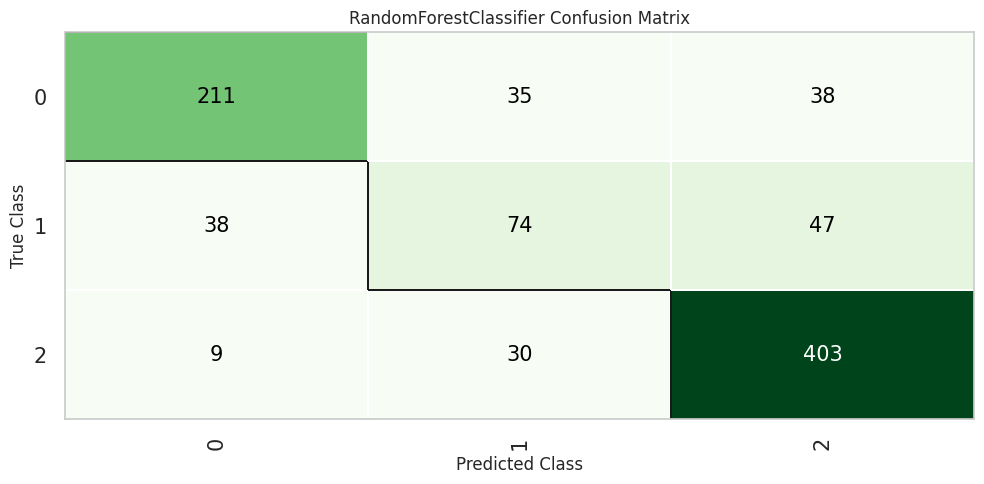

Gradient Boosting


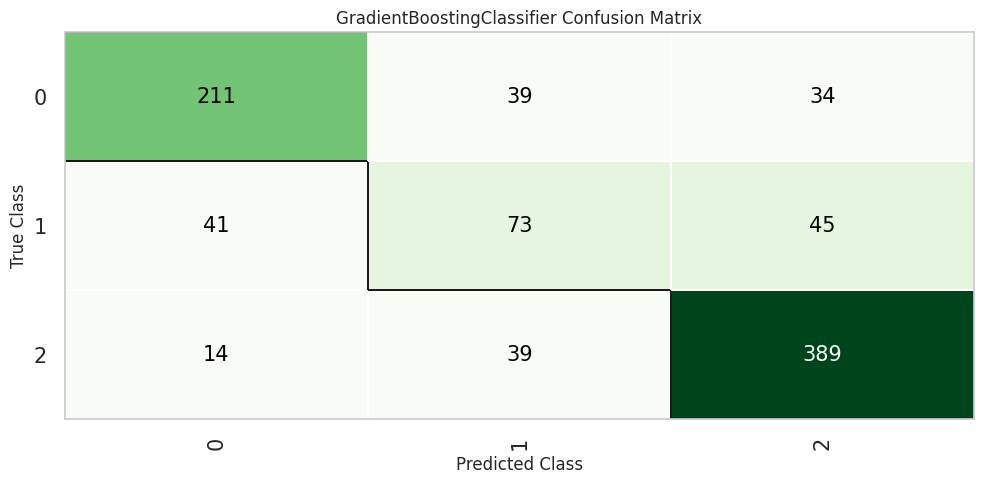

Logistic Regression


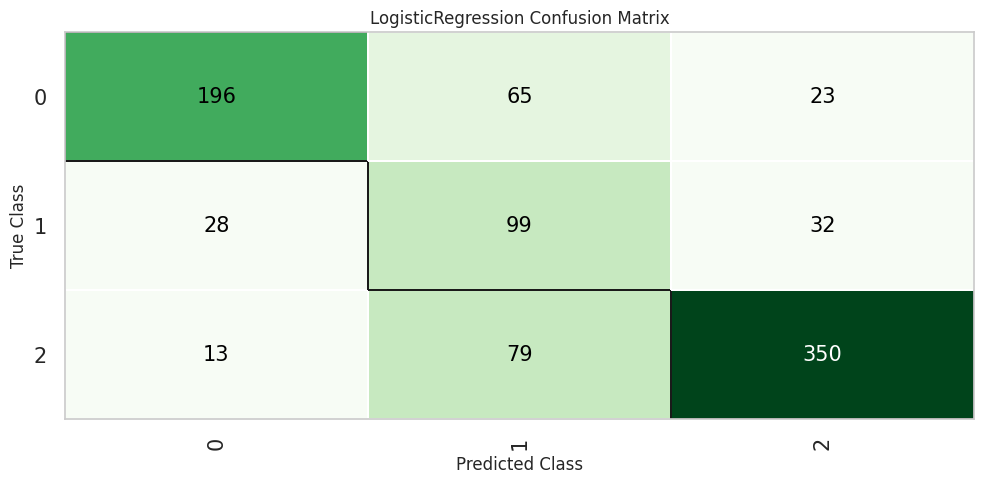

In [20]:
rf  = create_model("rf",  verbose=False)
gbc = create_model("gbc", verbose=False)
lr = create_model("lr", verbose=False)

for nombre, m in [("Random Forest", rf), ("Gradient Boosting", gbc), ("Logistic Regression", lr)]:
    print(nombre)
    plot_model(m, plot="confusion_matrix")

### Matrices de confusión de los tres candidatos (prueba, sin calibrar)

**Cómo leerlas:** filas = clase real; columnas = clase predicha; `0`=Dropout, `1`=Enrolled, `2`=Graduate. La **diagonal** son los aciertos; fuera de ella, los errores.

| Indicador | Random Forest | Gradient Boosting | Regresión Logística |
|---|---|---|---|
| Desertores detectados (de 284) | **211** | **211** | 196 |
| Desertores predichos como Graduate | 38 | 34 | **23** |
| Falsas alarmas de Dropout | 47 | 55 | **41** |
| Enrolled acertados (de 159) | 74 | 73 | **99** |
| Graduate acertados (de 442) | **403** | 389 | 350 |
| Aciertos totales (de 885) | **688** | 673 | 645 |

- **Random Forest** detecta tantos desertores como Gradient Boosting, con **8 falsas alarmas menos** y más aciertos totales.
- **Regresión Logística** reconoce mejor `Enrolled`, pero detecta 15 desertores menos y envía 79 graduados a `Enrolled`. Por otro lado, es la que menos desertores confunde con graduados.
- Ningún modelo gana en todo. La confusión de `Enrolled` con las otras clases aparece en los tres.

> Estas matrices son anteriores a la calibración; la del modelo final está en el anexo del Paso 8.

In [21]:
tabla_comparacion = pull()   # pull() devuelve la última tabla que mostró PyCaret
tabla_comparacion

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.713,0.000,0.713,0.740,0.724,0.543,0.546
1,0.757,0.000,0.757,0.777,0.765,0.613,0.615
2,0.754,0.000,0.754,0.780,0.764,0.610,0.614
3,0.756,0.000,0.756,0.773,0.762,0.611,0.612
4,0.745,0.000,0.745,0.774,0.756,0.595,0.599
Mean,0.745,0.000,0.745,0.769,0.754,0.595,0.597
Std,0.016,0.000,0.016,0.015,0.016,0.026,0.026


### Tabla por pliegue (`pull()`)

> Aunque la variable se llama `tabla_comparacion`, `pull()` devuelve la **última tabla** de PyCaret: los 5 pliegues de **Regresión Logística** (el último modelo creado). No compara varios modelos.

`Fold` 0–4 es cada pliegue; `Mean` y `Std` son promedio y desviación. Accuracy media 0.745 ± 0.016 y F1 ponderado 0.754 ± 0.016. El pliegue 0 es el más bajo (0.713 de accuracy).

## Paso 6 Explorar los mejores modelos

Miramos los 3 mejores con más detalle, revisando sus hiperparámetros, el comportamiento por pliegue, los errores por clase y las variables importantes. También se prueban otros algoritmos como `create_model("rf")`, `create_model("knn")` y `create_model("dt")`, y con `models()` se puede ver la lista de modelos disponibles.

In [22]:
import sklearn
from pycaret.classification import create_model

rf = create_model('rf')
modelos = [top3[0], top3[1], rf]

with sklearn.config_context(print_changed_only=False):
    for modelo in modelos:
        print(modelo, "\n")

,,
,,
Initiated,. . . . . . . . . . . . . . . . . .,07:55:56
Status,. . . . . . . . . . . . . . . . . .,Loading Dependencies
Estimator,. . . . . . . . . . . . . . . . . .,Compiling Library


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7585,0.8873,0.7585,0.7508,0.7482,0.5922,0.5996
1,0.7698,0.9082,0.7698,0.7578,0.7616,0.6170,0.6191
2,0.7895,0.9155,0.7895,0.7820,0.7824,0.6487,0.6525
3,0.7811,0.9015,0.7811,0.7737,0.7721,0.6317,0.6378
4,0.7921,0.9105,0.7921,0.7863,0.7858,0.6528,0.6568
Mean,0.7782,0.9046,0.7782,0.7701,0.7700,0.6285,0.6332
Std,0.0126,0.0098,0.0126,0.0137,0.0138,0.0222,0.0213


LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
                   intercept_scaling=1, l1_ratio=None, max_iter=1000,
                   multi_class='auto', n_jobs=None, penalty='l2',
                   random_state=42, solver='lbfgs', tol=0.0001, verbose=0,
                   warm_start=False) 

GradientBoostingClassifier(ccp_alpha=0.0, criterion='friedman_mse', init=None,
                           learning_rate=0.1, loss='log_loss', max_depth=3,
                           max_features=None, max_leaf_nodes=None,
                           min_impurity_decrease=0.0, min_samples_leaf=1,
                           min_samples_split=2, min_weight_fraction_leaf=0.0,
                           n_estimators=100, n_iter_no_change=None,
                           random_state=42, subsample=1.0, tol=0.0001,
                           validation_fraction=0.1, verbose=0,
                           warm_start=False) 

RandomForestClassifier(bootstrap=True, ccp_alpha=0

### Hiperparámetros de los modelos

La tabla superior corresponde a los pliegues de Random Forest. El texto muestra la configuración completa:

| Modelo | Cómo funciona | Parámetros principales |
|---|---|---|
| Regresión Logística | Combinación lineal de variables que produce probabilidades | `C=1.0`, penalización L2, `max_iter=1000` |
| Gradient Boosting | Árboles **en secuencia**; cada uno corrige errores anteriores | 100 árboles, `learning_rate=0.1`, `max_depth=3` |
| Random Forest | Muchos árboles **independientes** sobre muestras aleatorias; combina sus probabilidades | 100 árboles, criterio Gini, `max_features="sqrt"`, sin límite de profundidad |

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7585,0.8873,0.7585,0.7508,0.7482,0.5922,0.5996
1,0.7698,0.9082,0.7698,0.7578,0.7616,0.6170,0.6191
2,0.7895,0.9155,0.7895,0.7820,0.7824,0.6487,0.6525
3,0.7811,0.9015,0.7811,0.7737,0.7721,0.6317,0.6378
4,0.7921,0.9105,0.7921,0.7863,0.7858,0.6528,0.6568
Mean,0.7782,0.9046,0.7782,0.7701,0.7700,0.6285,0.6332
Std,0.0126,0.0098,0.0126,0.0137,0.0138,0.0222,0.0213


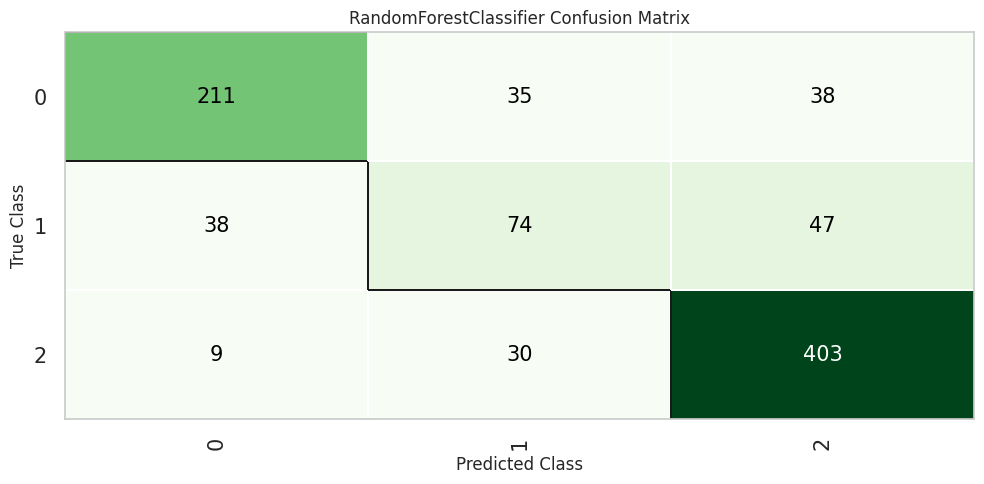

In [23]:
rf = create_model('rf')

plot_model(rf, plot="confusion_matrix")

### Random Forest: pliegues y matriz de confusión

| Métrica (CV de PyCaret) | Media | Desv. |
|---|---|---|
| Accuracy | 0.778 | 0.013 |
| AUC | 0.905 | 0.010 |
| F1 ponderado | 0.770 | 0.014 |
| Kappa | 0.629 | 0.022 |
| MCC | 0.633 | 0.021 |

La accuracy se mantiene entre 0.759 y 0.792 en los 5 pliegues: el modelo es **estable**. Estos valores son ponderados y de PyCaret, por eso no coinciden con el F1 **macro** (0.720).

**Matriz (prueba):** acierta 211/284 `Dropout`, 74/159 `Enrolled` y 403/442 `Graduate`.

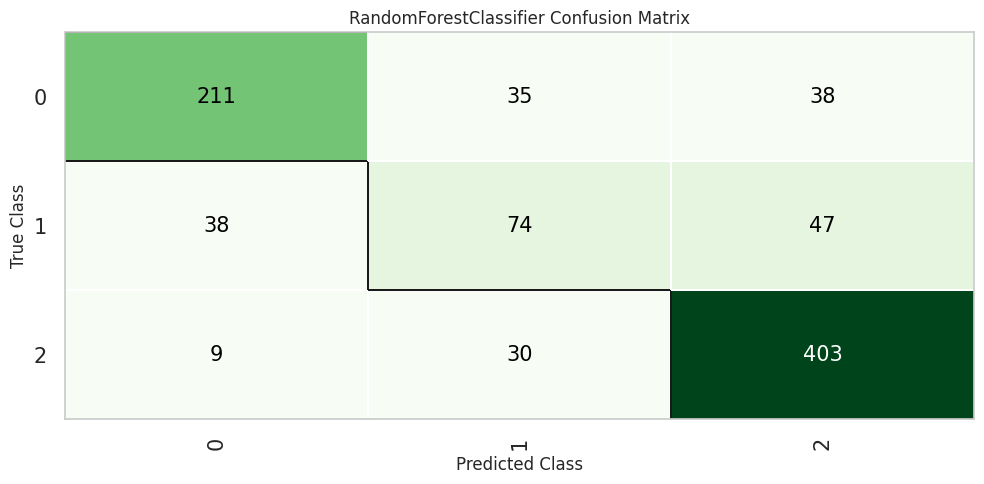

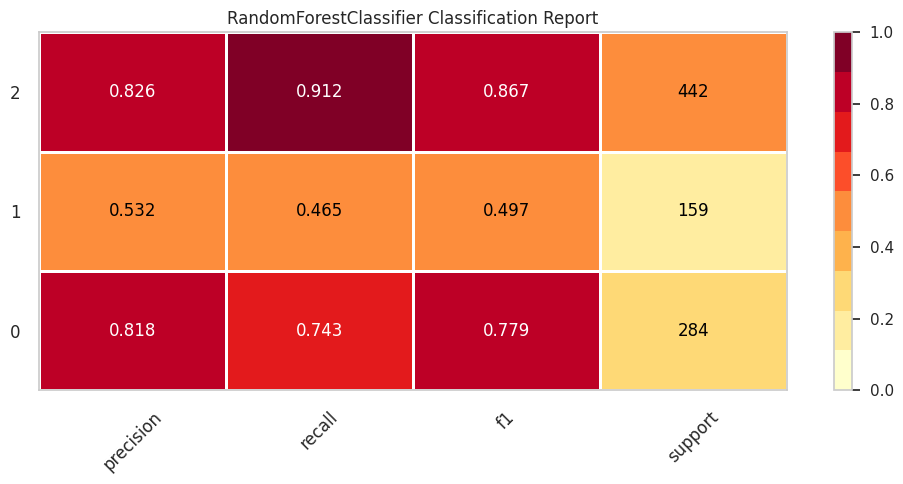

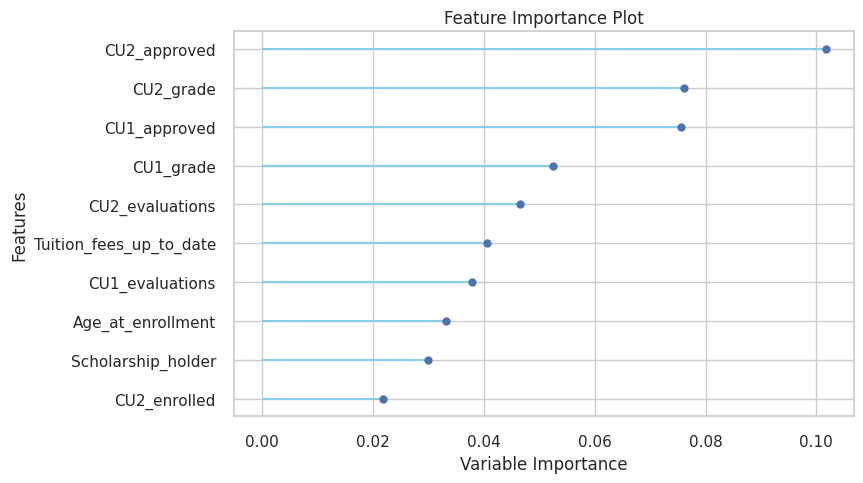

In [24]:
plot_model(rf, plot="confusion_matrix")   # dónde se confunde: Enrolled vs el resto
plot_model(rf, plot="class_report")       # precisión, recall y F1 por clase
plot_model(rf, plot="feature")            # variables más importantes

### Gráfica 1 · Matriz de confusión
- De los 73 desertores no detectados, 38 se predicen como `Graduate` y 35 como `Enrolled`.
- `Enrolled` es el principal problema: 47 se predicen como `Graduate` y 38 como `Dropout`, más errores (85) que aciertos (74).
- Solo 9 graduados se marcan como desertores.

### Gráfica 2 · Reporte de clasificación (sin calibrar)
Cada celda es una métrica por clase; los tonos más oscuros indican valores más altos. `support` es el número de casos reales.

| Clase | Precisión | Recall | F1 | Casos |
|---|---|---|---|---|
| 0 · Dropout | 0.818 | 0.743 | 0.779 | 284 |
| 1 · Enrolled | 0.532 | 0.465 | **0.497** | 159 |
| 2 · Graduate | 0.826 | **0.912** | **0.867** | 442 |

El modelo es bueno con `Graduate`, útil con `Dropout` y débil con `Enrolled`. El F1 macro baja precisamente por esta última clase.

### Gráfica 3 · Importancia de variables
Muestra cuánto aporta cada variable a las divisiones de los árboles (valores aproximados leídos de la gráfica).

| Puesto | Variable | Importancia aprox. | Qué mide |
|---|---|---|---|
| 1 | `CU2_approved` | 0.10 | Materias aprobadas, 2.º semestre |
| 2 | `CU2_grade` | 0.076 | Nota, 2.º semestre |
| 3 | `CU1_approved` | 0.075 | Materias aprobadas, 1.er semestre |
| 4 | `CU1_grade` | 0.052 | Nota, 1.er semestre |
| 5 | `CU2_evaluations` | 0.046 | Evaluaciones, 2.º semestre |
| 6 | `Tuition_fees_up_to_date` | 0.041 | Matrícula al día |
| 7 | `CU1_evaluations` | 0.038 | Evaluaciones, 1.er semestre |
| 8 | `Age_at_enrollment` | 0.033 | Edad al ingresar |
| 9 | `Scholarship_holder` | 0.030 | Tiene beca |
| 10 | `CU2_enrolled` | 0.022 | Materias inscritas, 2.º semestre |

Coincide con la exploración: pesa sobre todo el **rendimiento académico**, y también aparecen factores económicos.

> La importancia **no indica causalidad ni dirección** del efecto. Esta medida puede favorecer variables con muchos valores distintos, y el one-hot reparte la importancia de una categórica entre varias columnas.

In [25]:
rf = create_model('rf')
evaluate_model(rf)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7585,0.8873,0.7585,0.7508,0.7482,0.5922,0.5996
1,0.7698,0.9082,0.7698,0.7578,0.7616,0.6170,0.6191
2,0.7895,0.9155,0.7895,0.7820,0.7824,0.6487,0.6525
3,0.7811,0.9015,0.7811,0.7737,0.7721,0.6317,0.6378
4,0.7921,0.9105,0.7921,0.7863,0.7858,0.6528,0.6568
Mean,0.7782,0.9046,0.7782,0.7701,0.7700,0.6285,0.6332
Std,0.0126,0.0098,0.0126,0.0137,0.0138,0.0222,0.0213


interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

**`evaluate_model`:** abre un panel interactivo para cambiar entre gráficas (matriz de confusión, reporte, importancia, etc.).

In [26]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# setup SIN fix_imbalance, igual que en tu celda de validación cruzada
params = {k: v for k, v in CONFIGS["P4_smote"].items() if not k.startswith("fix_imbalance")}
setup(**BASE, **params)
X, y = get_config("X_train_transformed"), get_config("y_train_transformed")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

pipe = ImbPipeline([
    ("smote", SMOTE(random_state=SEMILLA)),
    ("clf", RandomForestClassifier(random_state=SEMILLA)),
])

espacio = {
    "clf__n_estimators":     [100, 200, 300, 500],
    "clf__max_depth":        [None, 10, 20, 30],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__max_features":     ["sqrt", "log2"],
}

busqueda = RandomizedSearchCV(
    pipe, espacio, n_iter=20, cv=cv, n_jobs=-1,
    scoring="f1_macro", random_state=SEMILLA,
)
busqueda.fit(X, y)

print("Mejores parámetros:", busqueda.best_params_)
print("F1 Macro (CV):", round(busqueda.best_score_, 3), "| base sin ajustar: 0.720")

Mejores parámetros: {'clf__n_estimators': 200, 'clf__min_samples_leaf': 1, 'clf__max_features': 'log2', 'clf__max_depth': 30}
F1 Macro (CV): 0.721 | base sin ajustar: 0.720


### Ajuste de hiperparámetros

`RandomizedSearchCV` probó **20 de las 96 combinaciones** posibles, optimizando F1 macro con SMOTE dentro de cada pliegue.

| Configuración | F1 macro (CV) |
|---|---|
| Random Forest por defecto | 0.720 |
| Mejor encontrada (200 árboles, `max_depth=30`, `max_features="log2"`, `min_samples_leaf=1`) | 0.721 |

**Decisión: conservar los valores por defecto.** La mejora de 0.001 es mucho menor que la variación entre pliegues (0.025) y no justifica un modelo más grande.

In [27]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import log_loss, f1_score, recall_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# setup SIN fix_imbalance: SMOTE lo aplica el pipeline dentro de cada pliegue
params = {k: v for k, v in CONFIGS["P4_smote"].items() if not k.startswith("fix_imbalance")}
setup(**BASE, **params)
X = get_config("X_train_transformed")
y = np.asarray(get_config("y_train_transformed"))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

def pipe():
    return ImbPipeline([("smote", SMOTE(random_state=SEMILLA)),
                        ("clf", RandomForestClassifier(random_state=SEMILLA))])

def brier(y_real, p):
    return np.mean(np.sum((p - np.eye(3)[y_real]) ** 2, axis=1))

# Calibrar envolviendo el pipeline: SMOTE solo ve los datos de entrenamiento y
# la calibración se ajusta con filas reales (sin sintéticas)
variantes = {
    "Sin calibrar": pipe(),
    "Sigmoid":      CalibratedClassifierCV(pipe(), method="sigmoid",  cv=5),
    "Isotonic":     CalibratedClassifierCV(pipe(), method="isotonic", cv=5),
}

filas, medias = {}, {}
for nombre, est in variantes.items():
    proba = cross_val_predict(est, X, y, cv=cv, method="predict_proba", n_jobs=-1)
    pred = proba.argmax(axis=1)
    filas[nombre] = {
        "Log loss": log_loss(y, proba),
        "Brier": brier(y, proba),
        "F1 Macro": f1_score(y, pred, average="macro"),
        "Recall Dropout": recall_score(y, pred, labels=[0], average="macro", zero_division=0),
    }
    medias[nombre] = proba.mean(axis=0)

medias["Frecuencia real"] = np.bincount(y) / len(y)

print("Métricas (CV, predicciones fuera de pliegue). Log loss y Brier: menor es mejor.")
display(pd.DataFrame(filas).T.round(3))
print("Probabilidad media predicha por clase vs. frecuencia real:")
display(pd.DataFrame(medias, index=["Dropout", "Enrolled", "Graduate"]).T.round(3))

# Restaurar el setup definitivo (con SMOTE)
exp = setup(**BASE, **CONFIGS["P4_smote"])

Métricas (CV, predicciones fuera de pliegue). Log loss y Brier: menor es mejor.


,Log loss,Brier,F1 Macro,Recall Dropout
Sin calibrar,0.637,0.324,0.720,0.761
Sigmoid,0.568,0.315,0.707,0.761
Isotonic,0.573,0.315,0.708,0.760


Probabilidad media predicha por clase vs. frecuencia real:


,Dropout,Enrolled,Graduate
Sin calibrar,0.314,0.213,0.473
Sigmoid,0.317,0.187,0.496
Isotonic,0.319,0.183,0.498
Frecuencia real,0.321,0.179,0.499


### Calibración de probabilidades

**Para qué:** que un porcentaje se parezca a la frecuencia real. Por ejemplo, entre estudiantes con 70 % de riesgo, cerca de 70 de cada 100 deberían desertar. Como SMOTE entrena con clases iguales, puede distorsionar las probabilidades.

- **Sigmoid:** ajusta una curva en forma de S (pocos parámetros).
- **Isotonic:** ajusta una función escalonada creciente (más flexible).

| Variante | Log loss ↓ | Brier ↓ | F1 macro | Recall Dropout |
|---|---|---|---|---|
| Sin calibrar | 0.637 | 0.324 | **0.720** | 0.761 |
| **Sigmoid** | **0.568** | **0.315** | 0.707 | 0.761 |
| Isotonic | 0.573 | 0.315 | 0.708 | 0.760 |

| Probabilidad media | Dropout | Enrolled | Graduate |
|---|---|---|---|
| Sin calibrar | 0.314 | **0.213** | 0.473 |
| Sigmoid | 0.317 | 0.187 | 0.496 |
| Isotonic | 0.319 | 0.183 | 0.498 |
| Frecuencia real | 0.321 | 0.179 | 0.499 |

- Sin calibrar, el modelo **sobrestima `Enrolled`** y **subestima `Graduate`**; `Dropout` queda cerca de lo real.
- **Sigmoid** reduce el log loss cerca de 11 % y mantiene el recall. Se elige por su menor log loss.
- Isotonic queda muy cerca (incluso sus promedios se acercan un poco más a la frecuencia real). La diferencia entre ambas es pequeña.
- **Costo:** F1 macro baja de 0.720 a 0.707.
- Comparar promedios es un control general; no sustituye una curva de calibración.

## Paso 7  Escoger el modelo

### Por qué se terminó usando Random Forest

En la CV (tabla de decisión del Paso 5), Random Forest tuvo el **F1 macro más alto (0.720)** y un Recall de Dropout de **0.761**. Sin embargo, **Gradient Boosting quedó prácticamente igual** (0.719 y 0.762) y tuvo un AUC apenas mayor (0.892 frente a 0.890). **Las métricas no demuestran que Random Forest sea superior.** Se escoge dentro de ese empate por estas razones:

| Razón | Evidencia |
|---|---|
| Cumple el criterio | Mayor F1 macro en CV, con recall a 0.001 del mejor |
| Entrena más rápido que Gradient Boosting | 1.2 s frente a 5.4 s en `compare_models` |
| El ajuste casi no cambia su resultado | 0.720 por defecto frente a 0.721 ajustado |
| Permite revisar la importancia de variables | Destaca rendimiento académico y matrícula al día |
| Comportamiento consistente en la exploración | En prueba, igual número de desertores detectados que Gradient Boosting y menos falsas alarmas (apoyo secundario, no criterio) |

**¿Y los demás?**
- **Regresión Logística** encabezó `compare_models` por Balanced Accuracy (0.710) y también tuvo la más alta en la tabla de decisión (0.714), pero con menor F1 macro (0.708) y menor recall de Dropout (0.742). Es una alternativa válida si se prioriza la simplicidad o reconocer `Enrolled`.
- **LDA** rindió menos en la revisión exploratoria sobre prueba.
- **Los demás modelos** quedaron por debajo en `compare_models`.

### Modelo elegido: Random Forest + SMOTE + calibración sigmoid

Random Forest con SMOTE y probabilidades calibradas (sigmoid). SMOTE iguala las clases al entrenar y eso infla las probabilidades de Enrolled y Dropout; la calibración las devuelve a su escala real. En CV, la calibración baja el log loss de 0.637 a 0.568 sin perder Recall de Dropout (0.761), con un costo pequeño en F1 macro (0.720 → 0.707).

### Sobre el uso del conjunto de prueba

La elección se **justifica con validación cruzada**. Sin embargo, durante la exploración el 20 % de prueba **sí se consultó** (balanceo, comparación preliminar y gráficas).

In [28]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, recall_score, balanced_accuracy_score, make_scorer
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

def evaluar_prueba(modelo):
    """Métricas sobre el 20 % de prueba. Usar UNA vez, con el modelo ya elegido."""
    X = get_config("X_test_transformed")
    y = get_config("y_test_transformed")
    pred = modelo.predict(X)
    return {
        "F1 Macro": round(f1_score(y, pred, average="macro", zero_division=0), 3),
        "Recall Dropout": round(recall_score(y, pred, labels=[0], average="macro", zero_division=0), 3),
        "Balanced Acc": round(balanced_accuracy_score(y, pred), 3),
    }

# 1. Setup definitivo SIN fix_imbalance: SMOTE va dentro del estimador
params = {k: v for k, v in CONFIGS["P4_smote"].items() if not k.startswith("fix_imbalance")}
exp = setup(**BASE, **params)

# 2. Random Forest + SMOTE, con probabilidades calibradas (sigmoid, calibración con filas reales)
estimador = CalibratedClassifierCV(
    ImbPipeline([("smote", SMOTE(random_state=SEMILLA)),
                 ("clf", RandomForestClassifier(random_state=SEMILLA))]),
    method="sigmoid", cv=5,
)
modelo_elegido = create_model(estimador, verbose=False)

# 3. Métricas de validación cruzada del modelo calibrado (5 pliegues, solo entrenamiento)
X, y = get_config("X_train_transformed"), get_config("y_train_transformed")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
rec_drop = make_scorer(recall_score, labels=[0], average="macro", zero_division=0)
r = cross_validate(estimador, X, y, cv=cv, n_jobs=-1,
                   scoring={"f1": "f1_macro", "rec": rec_drop, "bal": "balanced_accuracy"})
modelo_elegido.metricas_cv = {
    "Balanced Acc":   round(float(r["test_bal"].mean()), 3),
    "F1 (std)":       round(float(r["test_f1"].std()), 3),
    "F1 Macro":       round(float(r["test_f1"].mean()), 3),
    "Recall (std)":   round(float(r["test_rec"].std()), 3),
    "Recall Dropout": round(float(r["test_rec"].mean()), 3),
}
print("CV:", modelo_elegido.metricas_cv)

# 4. Única mirada al set de prueba para la decisión final
print("Prueba:", evaluar_prueba(modelo_elegido))

# 5. Comprobación de calibración en prueba: probabilidad media predicha vs frecuencia real
proba_te = modelo_elegido.predict_proba(get_config("X_test_transformed")).mean(axis=0)
real_te = np.bincount(get_config("y_test_transformed")) / len(get_config("y_test_transformed"))
print("Prob. media  [Dropout, Enrolled, Graduate]:", proba_te.round(3))
print("Frec. real   [Dropout, Enrolled, Graduate]:", real_te.round(3))

CV: {'Balanced Acc': 0.697, 'F1 (std)': 0.022, 'F1 Macro': 0.706, 'Recall (std)': 0.021, 'Recall Dropout': 0.761}
Prueba: {'F1 Macro': 0.715, 'Recall Dropout': 0.764, 'Balanced Acc': 0.707}
Prob. media  [Dropout, Enrolled, Graduate]: [0.318 0.197 0.485]
Frec. real   [Dropout, Enrolled, Graduate]: [0.321 0.18  0.499]


### Resultado del modelo elegido

| Métrica | CV (± desv.) | Prueba |
|---|---|---|
| F1 macro | 0.706 ± 0.022 | 0.715 |
| Recall Dropout | 0.761 ± 0.021 | 0.764 |
| Balanced Acc | 0.697 | 0.707 |

- CV y prueba son **muy parecidas**: no hay señales de una caída al pasar a los datos de prueba.
- El 0.706 difiere del 0.707 de la tabla de calibración porque aquí se **promedian las métricas de cada pliegue** y allí se calcula una sola vez sobre todas las predicciones juntas.

| Calibración en prueba | Dropout | Enrolled | Graduate |
|---|---|---|---|
| Probabilidad media predicha | 0.318 | 0.197 | 0.485 |
| Frecuencia real | 0.321 | 0.180 | 0.499 |

La mayor diferencia es de 1.7 puntos porcentuales (`Enrolled`).

## Paso 8 · Evaluar con los datos de prueba

Se mide el modelo elegido con el 20 % de datos que **no** usó para entrenar (ver en el Paso 7 la advertencia sobre su uso durante la exploración). Estas son las métricas de prueba que se exportan para la app.

In [29]:
predicciones = predict_model(modelo_elegido)
metricas_prueba = pull()
metricas_prueba

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.7785,0.9070,0.7785,0.7705,0.7725,0.6323,0.6345


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.778,0.907,0.778,0.770,0.772,0.632,0.634


### Métricas de PyCaret en prueba

| Accuracy | AUC | Recall | Prec. | F1 | Kappa | MCC |
|---|---|---|---|---|---|---|
| 0.778 | 0.907 | 0.778 | 0.770 | 0.772 | 0.632 | 0.634 |

Recall, Prec. y F1 son **ponderados**. No deben confundirse con el recall de Dropout (0.764) ni con el F1 macro (0.715).

In [30]:
predicciones.head()

,Marital_status,Application_mode,Application_order,Course,Daytime_attendance,Previous_qualification,Nationality,Mothers_qualification,Fathers_qualification,Mothers_occupation,...,CU2_evaluations,CU2_approved,CU2_grade,CU2_no_evals,Unemployment_rate,Inflation_rate,GDP,Target,prediction_label,prediction_score
1853,1,44,1,9003,1,39,1,3,3,2,...,7,6,14.667,0,12.400,0.500,1.790,Graduate,Graduate,0.888
2399,1,17,1,9500,1,1,1,1,1,5,...,10,8,11.712,0,16.200,0.300,-0.920,Graduate,Graduate,0.789
510,1,1,2,9070,1,1,1,4,1,2,...,9,0,0.000,0,9.400,-0.800,-3.120,Enrolled,Dropout,0.767
242,1,1,2,9147,1,1,1,37,19,5,...,5,5,13.600,0,12.400,0.500,1.790,Graduate,Graduate,0.907
3392,1,1,1,9070,1,1,1,1,1,9,...,6,6,12.667,0,16.200,0.300,-0.920,Graduate,Graduate,0.903


**Tabla `predicciones.head()`:** muestra 5 estudiantes de prueba con sus variables, la clase real (`Target`), la clase predicha (`prediction_label`) y `prediction_score`, que es la probabilidad asignada a la clase predicha. Son ejemplos y no resumen el rendimiento.

In [31]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, recall_score, balanced_accuracy_score

# Datos de prueba ya transformados y predicciones del modelo elegido
X_t = get_config("X_test_transformed")
y_t = np.asarray(get_config("y_test_transformed"))
pred = np.asarray(modelo_elegido.predict(X_t))

# Las tres métricas (Dropout = clase 0 dentro de PyCaret)
metricas_fn = {
    "F1 Macro":       lambda y, p: f1_score(y, p, average="macro", zero_division=0),
    "Recall Dropout": lambda y, p: recall_score(y, p, labels=[0], average="macro", zero_division=0),
    "Balanced Acc":   lambda y, p: balanced_accuracy_score(y, p),
}

# Bootstrap: remuestrear las filas de prueba con reemplazo
rng = np.random.default_rng(SEMILLA)
N_BOOT = 2000
muestras = [rng.integers(0, len(y_t), len(y_t)) for _ in range(N_BOOT)]

filas_ic = {}
for nombre, fn in metricas_fn.items():
    valores = [fn(y_t[idx], pred[idx]) for idx in muestras]
    bajo, alto = np.percentile(valores, [2.5, 97.5])
    filas_ic[nombre] = {
        "Estimado": fn(y_t, pred),
        "IC 95 % inf": bajo,
        "IC 95 % sup": alto,
        "Ancho": alto - bajo,
    }

ic_prueba = pd.DataFrame(filas_ic).T.round(3)
print(f"Filas de prueba: {len(y_t)} | remuestreos: {N_BOOT}")
ic_prueba

Filas de prueba: 885 | remuestreos: 2000


,Estimado,IC 95 % inf,IC 95 % sup,Ancho
F1 Macro,0.715,0.682,0.747,0.065
Recall Dropout,0.764,0.714,0.812,0.099
Balanced Acc,0.707,0.675,0.739,0.063


### Intervalos de confianza (bootstrap)

Se remuestrean 2000 veces, con reemplazo, las 885 filas de prueba, y se toma el rango central del 95 %.

| Métrica | Estimado | IC 95 % | Ancho |
|---|---|---|---|
| F1 macro | 0.715 | 0.682 – 0.747 | 0.065 |
| Recall Dropout | 0.764 | 0.714 – 0.812 | 0.099 |
| Balanced Acc | 0.707 | 0.675 – 0.739 | 0.063 |

El recall tiene el intervalo más ancho porque se calcula solo con 284 desertores. Conviene reportarlo como **aproximadamente entre 71 % y 81 %**. Este intervalo refleja la variación de la muestra de prueba, no la de volver a entrenar ni la de aplicar el modelo en otra institución o periodo.

In [32]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

nombres = ["Dropout", "Enrolled", "Graduate"]
X_t = get_config("X_test_transformed")
y_t = np.asarray(get_config("y_test_transformed"))
pred = np.asarray(modelo_elegido.predict(X_t))

# 1. Matriz de confusión (filas = lo que pasó, columnas = lo que predijo el modelo)
cm = pd.DataFrame(confusion_matrix(y_t, pred),
                  index=[f"real {n}" for n in nombres],
                  columns=[f"pred {n}" for n in nombres])
display(cm)

# 2. Precisión, recall y F1 por clase
print(classification_report(y_t, pred, target_names=nombres, digits=3))

# 3. Resumen en palabras para Dropout
n_drop      = int((y_t == 0).sum())
detectados  = int(((y_t == 0) & (pred == 0)).sum())
alertas     = int((pred == 0).sum())
falsas      = alertas - detectados
base        = n_drop / len(y_t)

print(f"Desertores reales en prueba: {n_drop}")
print(f"  Detectados: {detectados} ({detectados/n_drop:.0%}) | No detectados: {n_drop - detectados}")
print(f"Alertas emitidas: {alertas} -> {detectados} aciertos y {falsas} falsas alarmas "
      f"(precisión {detectados/alertas:.0%})")
print(f"Azar: marcar al azar acertaría ~{base:.0%} de las veces -> "
      f"el modelo multiplica el acierto por {detectados/alertas/base:.1f}")

,pred Dropout,pred Enrolled,pred Graduate
real Dropout,217,30,37
real Enrolled,37,72,50
real Graduate,10,32,400


              precision    recall  f1-score   support

     Dropout      0.822     0.764     0.792       284
    Enrolled      0.537     0.453     0.491       159
    Graduate      0.821     0.905     0.861       442

    accuracy                          0.779       885
   macro avg      0.727     0.707     0.715       885
weighted avg      0.771     0.779     0.773       885

Desertores reales en prueba: 284
  Detectados: 217 (76%) | No detectados: 67
Alertas emitidas: 264 -> 217 aciertos y 47 falsas alarmas (precisión 82%)
Azar: marcar al azar acertaría ~32% de las veces -> el modelo multiplica el acierto por 2.6


## Anexo · ¿El modelo detecta a los que van a desertar?

Resultados sobre el 20 % de prueba (885 estudiantes) con el modelo exportado (Random Forest + SMOTE, calibrado). Explica las tres salidas de la celda anterior.

### Matriz de confusión

| | pred Dropout | pred Enrolled | pred Graduate |
|---|---|---|---|
| **real Dropout** | **217** | 30 | 37 |
| **real Enrolled** | 37 | **72** | 50 |
| **real Graduate** | 10 | 32 | **400** |

Comparado con Random Forest sin calibrar, detecta 6 desertores más (217 frente a 211) y mantiene 47 falsas alarmas.

### Reporte por clase

| Clase | Precisión | Recall | F1 | Casos |
|---|---|---|---|---|
| Dropout | 0.822 | 0.764 | 0.792 | 284 |
| Enrolled | 0.537 | 0.453 | 0.491 | 159 |
| Graduate | 0.821 | 0.905 | 0.861 | 442 |
| **Promedio macro** | 0.727 | 0.707 | 0.715 | 885 |
| Promedio ponderado | 0.771 | 0.779 | 0.773 | 885 |

Accuracy: 0.779. El promedio **macro** trata igual a las clases; el **ponderado** da más peso a las grandes y por eso es más alto.

### Resultados para Dropout

| Medida | Valor |
|---|---|
| Desertores reales | 284 |
| Detectados (recall) | 217 (76 %) |
| No detectados | 67 |
| Alertas emitidas | 264 |
| Aciertos / falsas alarmas | 217 / 47 |
| Precisión | 82 % |
| Precisión esperada al marcar al azar | ~32 % |

La precisión de las alertas es **2.6 veces** la esperada al azar (82 % frente a 32 %).

### Los desertores que se escapan
De los 67 no detectados, 37 se predicen como `Graduate` y 30 como `Enrolled`. Los 37 son los más preocupantes porque el modelo los clasifica como graduados. Una **hipótesis, no verificada**, es que tuvieran buen rendimiento en el 1.er año.

### Las falsas alarmas
De las 47, 10 son `Graduate` y 37 son `Enrolled`. Los `Enrolled` aún no tienen un desenlace final en estos datos; no se puede saber si estaban realmente en riesgo.

### Punto débil: la clase Enrolled
- Recall: 72 de 159 (45 %).
- Precisión: 72 de 134 (54 %).

Es la clase menos confiable; sus predicciones deben tomarse con cautela.

### Cómo reportarlo
> En los datos de prueba, el modelo detecta entre 7 y 8 de cada 10 desertores, y unas 8 de cada 10 alertas son correctas. La clase `Enrolled` es poco fiable.

El recall de Dropout es 0.764, con IC 95 % de **0.714 a 0.812**.

### Posible mejora futura
Ajustar el umbral de decisión (por ejemplo, marcar riesgo si la probabilidad de Dropout supera 30 %) para subir el recall a costa de más falsas alarmas. El umbral debe elegirse con validación cruzada, no con el conjunto de prueba.

## Paso 9 · Exportar el modelo

Se guarda el modelo **tal como se evaluó**: Random Forest entrenado con el 80 % de los datos, con SMOTE y calibración. No se reentrena con el 20 % de prueba, así que las métricas mostradas corresponden al modelo exportado.

Se guardan dos archivos en `modelo/`:

- `NOMBRE_MODELO.pkl` → pipeline de PyCaret (preprocesamiento + modelo calibrado).
- `metricas.json` → información para la app: algoritmo y métricas; las celdas siguientes añaden columnas, clases, rangos, intervalos de confianza, tipos y categorías.

> En el JSON el algoritmo aparece como `CalibratedClassifierCV`, que es la envoltura de calibración. Por dentro combina 5 pipelines SMOTE + Random Forest (`cv=5`).

In [33]:
import json
from sklearn.metrics import f1_score, recall_score, balanced_accuracy_score

# 1. Métricas sobre el 20 % de prueba
predicciones = predict_model(modelo_elegido, verbose=False)
y_real = predicciones["Target"]
y_pred = predicciones["prediction_label"]

metricas = {
    "algoritmo": type(modelo_elegido).__name__,
    "validacion_cruzada": modelo_elegido.metricas_cv,
    "prueba": {
        "F1 Macro":       round(f1_score(y_real, y_pred, average="macro"), 3),
        "Recall Dropout": round(recall_score(y_real, y_pred, labels=["Dropout"], average="macro", zero_division=0), 3),
        "Balanced Acc":   round(balanced_accuracy_score(y_real, y_pred), 3),
    },
}

# 2. Guardar el modelo tal cual (entrenado con el 80 % de los datos)
CARPETA_MODELO.mkdir(exist_ok=True)
save_model(modelo_elegido, str(CARPETA_MODELO / NOMBRE_MODELO))

# 3. Guardar las métricas
with open(CARPETA_MODELO / "metricas.json", "w", encoding="utf-8") as f:
    json.dump(metricas, f, indent=2, ensure_ascii=False)

print(json.dumps(metricas, indent=2, ensure_ascii=False))

Transformation Pipeline and Model Successfully Saved
{
  "algoritmo": "CalibratedClassifierCV",
  "validacion_cruzada": {
    "Balanced Acc": 0.697,
    "F1 (std)": 0.022,
    "F1 Macro": 0.706,
    "Recall (std)": 0.021,
    "Recall Dropout": 0.761
  },
  "prueba": {
    "F1 Macro": 0.715,
    "Recall Dropout": 0.764,
    "Balanced Acc": 0.707
  }
}


In [34]:
import json
from datetime import datetime

ruta_json = CARPETA_MODELO / "metricas.json"

# Partimos del JSON que ya escribió el Paso 9 (algoritmo, validacion_cruzada, prueba)
metricas = json.loads(ruta_json.read_text(encoding="utf-8"))

# Variables de entrada reales del modelo (34, sin Target ni las 2 columnas eliminadas)
columnas_entrada = [c for c in df.columns if c != "Target"]

metricas.update({
    "columnas": columnas_entrada,
    "clases": sorted(df["Target"].unique().tolist()),
    "rangos": {c: [float(df[c].min()), float(df[c].max())] for c in columnas_entrada},
    "prueba_ic95": {
        nombre: [float(fila["IC 95 % inf"]), float(fila["IC 95 % sup"])]
        for nombre, fila in ic_prueba.iterrows()
    },
    "fecha": datetime.now().strftime("%Y-%m-%d %H:%M"),
})

ruta_json.write_text(json.dumps(metricas, indent=2, ensure_ascii=False), encoding="utf-8")

print(metricas["algoritmo"], "|", len(metricas["columnas"]), "columnas")
print(metricas["validacion_cruzada"])
print(metricas["prueba"])

CalibratedClassifierCV | 34 columnas
{'Balanced Acc': 0.697, 'F1 (std)': 0.022, 'F1 Macro': 0.706, 'Recall (std)': 0.021, 'Recall Dropout': 0.761}
{'F1 Macro': 0.715, 'Recall Dropout': 0.764, 'Balanced Acc': 0.707}


**Salida:** confirma que el JSON quedó con el modelo calibrado, sus **34 columnas de entrada** y las métricas de CV y prueba. También agrega los rangos de cada variable, los intervalos de confianza y la fecha.

## Paso 10 · Probar el modelo exportado

Cargamos el modelo guardado en `modelo/` y lo probamos con tres estudiantes de ejemplo, tal como lo haría la app.

In [35]:
import numpy as np
import pandas as pd
from pycaret.classification import load_model, predict_model, get_config

modelo_cargado = load_model(str(CARPETA_MODELO / NOMBRE_MODELO))

# Las 885 filas de prueba (datos crudos, 34 columnas) y su clase real
X_prueba = get_config("X_test")
reales = get_config("y_test").astype(str).to_numpy()
assert len(X_prueba) == 885, f"Se esperaban 885 filas de prueba y hay {len(X_prueba)}"

# raw_score=True devuelve la probabilidad de cada clase
res = predict_model(modelo_cargado, data=X_prueba, raw_score=True, verbose=False)

clases = ["Dropout", "Enrolled", "Graduate"]
pred = res["prediction_label"].astype(str).to_numpy()

tabla = pd.DataFrame({
    "Real": reales,
    "Predicho": pred,
    **{f"P({c})": (res[f"prediction_score_{c}"] * 100).round().astype(int).to_numpy() for c in clases},
    "Resultado": np.where(reales == pred, "✅", "❌"),
}, index=X_prueba.index).sort_values("P(Dropout)", ascending=False)

# Resumen de la meta: detectar desertores
desertores = (reales == "Dropout").sum()
detectados = ((reales == "Dropout") & (pred == "Dropout")).sum()
alertas = (pred == "Dropout").sum()
falsas = alertas - detectados

print(f"Estudiantes de prueba: {len(reales)}")
print(f"Desertores reales: {desertores}")
print(f"  Detectados: {detectados} ({detectados/desertores:.0%}) | No detectados: {desertores - detectados}")
print(f"Alertas emitidas: {alertas} -> {detectados} aciertos y {falsas} falsas alarmas "
      f"(precisión {detectados/alertas:.0%})")

tabla.to_csv("predicciones_prueba_885.csv", index_label="fila")   # tabla completa en un archivo
display(tabla)

Transformation Pipeline and Model Successfully Loaded
Estudiantes de prueba: 885
Desertores reales: 284
  Detectados: 217 (76%) | No detectados: 67
Alertas emitidas: 264 -> 217 aciertos y 47 falsas alarmas (precisión 82%)


,Real,Predicho,P(Dropout),P(Enrolled),P(Graduate),Resultado
2340,Dropout,Dropout,94,3,3,✅
4034,Dropout,Dropout,94,3,3,✅
477,Dropout,Dropout,94,3,3,✅
3314,Dropout,Dropout,93,4,3,✅
893,Dropout,Dropout,93,4,3,✅
...,...,...,...,...,...,...
450,Graduate,Graduate,3,4,93,✅
1984,Graduate,Graduate,3,3,93,✅
3301,Graduate,Graduate,3,4,93,✅
1070,Graduate,Graduate,3,4,93,✅


### Prueba de tres estudiantes con el modelo cargado

| Estudiante | Real | Predicho | P(Dropout) | P(Enrolled) | P(Graduate) | Resultado |
|---|---|---|---|---|---|---|
| 1 | Graduate | Graduate | 6 % | 5 % | 89 % | ✅ |
| 2 | Graduate | Graduate | 7 % | 14 % | 79 % | ✅ |
| 3 | Enrolled | Dropout | 77 % | 18 % | 5 % | ❌ |

Comprueba que el modelo **carga y predice** correctamente. El tercer caso muestra que una probabilidad alta no garantiza acierto y refleja la dificultad con `Enrolled`. Tres casos **no miden** el rendimiento.

In [36]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

cu1 = [c for c in df_modelo.columns if c.startswith("CU1_")]
cu2 = [c for c in df_modelo.columns if c.startswith("CU2_")]
print(f"CU1: {len(cu1)} columnas | CU2: {len(cu2)} columnas")

variantes = {
    "Completo (fin 1.er año)":        df_modelo,
    "Sin CU2 (fin 1.er semestre)":    df_modelo.drop(columns=cu2),
    "Sin CU1 ni CU2 (al ingresar)":   df_modelo.drop(columns=cu1 + cu2),
}

params = {k: v for k, v in CONFIGS["P4_smote"].items() if not k.startswith("fix_imbalance")}
rec_drop = make_scorer(recall_score, labels=[0], average="macro", zero_division=0)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

filas = {}
for etiqueta, datos in variantes.items():
    setup(**{**BASE, "data": datos}, **params)
    X, y = get_config("X_train_transformed"), get_config("y_train_transformed")
    pipe = ImbPipeline([("smote", SMOTE(random_state=SEMILLA)),
                        ("clf", RandomForestClassifier(random_state=SEMILLA))])
    r = cross_validate(pipe, X, y, cv=cv, n_jobs=-1,
                       scoring={"f1": "f1_macro", "rec": rec_drop, "bal": "balanced_accuracy"})
    filas[etiqueta] = {
        "Variables": datos.shape[1] - 1,
        "F1 Macro": r["test_f1"].mean(), "F1 (std)": r["test_f1"].std(),
        "Recall Dropout": r["test_rec"].mean(), "Recall (std)": r["test_rec"].std(),
        "Balanced Acc": r["test_bal"].mean(),
    }

display(pd.DataFrame(filas).T.round(3))

# Restaurar el setup del modelo exportado (SMOTE va dentro del estimador, no en setup)
exp = setup(**BASE, **params)

CU1: 6 columnas | CU2: 6 columnas


,Variables,F1 Macro,F1 (std),Recall Dropout,Recall (std),Balanced Acc
Completo (fin 1.er año),34.000,0.720,0.025,0.761,0.021,0.711
Sin CU2 (fin 1.er semestre),28.000,0.674,0.018,0.737,0.024,0.666
Sin CU1 ni CU2 (al ingresar),22.000,0.542,0.020,0.601,0.033,0.540


## Anexo · ¿Qué tan temprano se puede predecir?

El modelo exportado usa datos del 1.er y 2.º semestre (`CU1_*`, `CU2_*`), así que se aplica **al final del primer año**. Para ver cuánto se pierde al predecir antes, se repitió la CV (5 pliegues, Random Forest + SMOTE, **sin calibrar**) quitando variables. Corresponde a la tabla de la celda anterior:

| Momento de predicción | Variables | F1 macro (± desv.) | Recall Dropout (± desv.) | Balanced Acc |
|---|---|---|---|---|
| Fin del 1.er año | 34 | 0.720 ± 0.025 | 0.761 ± 0.021 | 0.711 |
| Fin del 1.er semestre (sin `CU2_*`) | 28 | 0.674 ± 0.018 | 0.737 ± 0.024 | 0.666 |
| Al ingresar (sin `CU1_*` ni `CU2_*`) | 22 | 0.542 ± 0.020 | 0.601 ± 0.033 | 0.540 |

**Conclusiones:**
- Predecir un semestre antes cuesta cerca de 0.05 de F1 macro. El recall baja 0.024, una diferencia del orden de la variación entre pliegues.
- Solo con datos de ingreso el desempeño cae bastante. Supera a un modelo que siempre responda la clase mayoritaria (F1 macro ≈ 0.22), pero detecta cerca de 6 de cada 10 desertores; no se midió su precisión de alertas.
- **Mejora futura:** exportar un segundo modelo sin `CU2_*` para avisar al final del 1.er semestre, midiendo antes sus falsas alarmas.

 **Listo.** Ahora abre la app en la terminal:

```bash
uv run app
```

Si vuelves a ejecutar este cuaderno y escoges otro modelo, la app usará el nuevo la próxima vez que la abras. Para el instalador, repite PyInstaller e Inno Setup (ver README).

In [37]:
import json
from datetime import datetime

ruta_json = CARPETA_MODELO / "metricas.json"

# Partimos del JSON que ya escribió el Paso 9 (algoritmo, validacion_cruzada, prueba)
metricas = json.loads(ruta_json.read_text(encoding="utf-8"))

# Variables de entrada reales del modelo (34, sin Target ni las 2 columnas eliminadas)
columnas_entrada = [c for c in df.columns if c != "Target"]

metricas.update({
    "columnas": columnas_entrada,
    "clases": sorted(df["Target"].unique().tolist()),
    "rangos": {c: [float(df[c].min()), float(df[c].max())] for c in columnas_entrada},
    "prueba_ic95": {
        nombre: [float(fila["IC 95 % inf"]), float(fila["IC 95 % sup"])]
        for nombre, fila in ic_prueba.iterrows()
    },
    "tipos": {
        c: ("binaria" if c in bin_cols else
            "ordinal" if c in ord_cols else
            "nominal" if c in nom_cols else
            "numerica")
        for c in columnas_entrada
    },
    "categorias": {c: sorted(df[c].astype(str).unique().tolist(), key=int) for c in nom_cols},
    "fecha": datetime.now().strftime("%Y-%m-%d %H:%M"),
})

ruta_json.write_text(json.dumps(metricas, indent=2, ensure_ascii=False), encoding="utf-8")

print(metricas["algoritmo"], "|", len(metricas["columnas"]), "columnas")
print(metricas["validacion_cruzada"])
print(metricas["prueba"])
print("Tipos:", {t: sum(v == t for v in metricas["tipos"].values())
                 for t in ["binaria", "ordinal", "nominal", "numerica"]})

CalibratedClassifierCV | 34 columnas
{'Balanced Acc': 0.697, 'F1 (std)': 0.022, 'F1 Macro': 0.706, 'Recall (std)': 0.021, 'Recall Dropout': 0.761}
{'F1 Macro': 0.715, 'Recall Dropout': 0.764, 'Balanced Acc': 0.707}
Tipos: {'binaria': 8, 'ordinal': 1, 'nominal': 9, 'numerica': 16}


**Salida final:** completa `metricas.json` con el tipo de cada variable (8 binarias, 1 ordinal, 9 nominales, 16 numéricas) y las categorías válidas de las nominales.

---

## Conclusiones y limitaciones

### Flujo completo

| Etapa | Decisión | Motivo |
|---|---|---|
| Datos | 4424 estudiantes, 34 variables | Sin nulos ni duplicados |
| Partición | 80 / 20 estratificada | Reservar datos de prueba |
| Preprocesamiento | Mediana, categorías raras, one-hot, z-score | Preparar variables mixtas (103 columnas) |
| Balanceo | SMOTE, solo en entrenamiento | En CV con RF: F1 macro 0.685 → 0.720 |
| Métricas | Recall y precisión de `Dropout`, F1 macro | Detectar desertores sin descuidar alertas ni clases |
| Modelo | Random Forest | Empate técnico con Gradient Boosting, pero más rápido |
| Hiperparámetros | Por defecto | El ajuste solo sumó 0.001 |
| Calibración | Sigmoid | Log loss 0.637 → 0.568 |

### Conclusiones

1. **El rendimiento académico es la señal dominante.** Las materias aprobadas y las notas de ambos semestres son las variables con mayor importancia. Los factores económicos como la matrícula al día y la beca aportan menos. Estas son asociaciones encontradas por el modelo, no causas.

2. **El modelo detecta una mayoría de desertores, pero no a todos.** El Recall de `Dropout` es de **0.764**, con un intervalo de **0.714 a 0.812**. Por eso es más adecuado decir que el modelo detecta **entre 7 y 8 de cada 10 desertores**, en lugar de tomar el 0.764 como un valor exacto.

3. **SMOTE mejora el equilibrio entre clases.** El F1 macro aumentó de **0.685 a 0.720** en validación cruzada con Random Forest, sin una pérdida clara en el Recall de `Dropout`.

4. **La calibración mejora las probabilidades, pero cuesta rendimiento.** El log loss disminuye de **0.637 a 0.568**, pero el F1 macro baja de **0.720 a 0.707** en validación cruzada. Por eso la calibración se justifica si la institución va a utilizar los porcentajes de riesgo. Si solo se utiliza la clase predicha, no aporta una mejora en el rendimiento de clasificación.

### Limitaciones

1. El 20 % de prueba se consultó durante la exploración (balanceo, comparación de modelos y gráficas). Sus métricas pueden ser algo optimistas.

2. La función `setup()` ajusta el escalado y las categorías raras con todo el entrenamiento antes de dividir en pliegues. Las validaciones cruzadas manuales pueden ser algo optimistas.

3. **Hipótesis no verificada:** las variables del 2.º semestre pueden depender en parte de que el estudiante ya haya abandonado, porque quien deserta tiene pocas materias evaluadas y aprobadas. Si es así, el rendimiento al final del primer año estaría inflado y sería menos útil para prevenir.

4. `Enrolled` es un estado intermedio: el estudiante aún puede graduarse o desertar. Su baja precisión es en parte estructural y no solo del modelo.

5. No hay prueba estadística entre modelos, y por eso el empate técnico impide hablar de un ganador.

